# 空间转录组基本分析

In [1]:
from datetime import date
print("Author: Biomamba_pudding")
print("Date:", date.today())

Author: Biomamba_pudding
Date: 2025-10-14


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、基本分析

空转转录组的分析主要使用R、python。由于Visium HD的超高的spot数量，在8bin的情况下整个表达矩阵包含了近 37w 个spot，因此我们后续的分析使用16bin矩阵完成（大约有9w+）

## 1. 加载所需库与软件

In [2]:
import os            # 操作系统接口，用于文件路径、环境等
import re            # 正则表达式模块，用于字符串模式匹配
import json          # 用于处理 JSON 数据
import numpy as np   # 科学计算基础库，支持多维数组和矩阵运算
import pandas as pd  # 数据处理和分析库，核心数据结构为 DataFrame
import scanpy as sc  # 专注于单细胞基因表达数据分析的工具包
import squidpy as sq # 专注于空间分子数据（如空间转录组学）分析的工具包
import seaborn as sns# 基于 matplotlib 的统计数据可视化库
import matplotlib.pyplot as plt # 基础绘图库，提供 MATLAB 风格的绘图接口
from PIL import Image# Python Imaging Library (Pillow)，用于图像处理功能

print(f"squidpy=={sq.__version__}") # 打印版本号
print(f"scanpy=={sc.__version__}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")

squidpy==1.6.5
scanpy==1.9.3
pandas==2.2.3
numpy==1.26.4


## 2. 构建基础对象

In [ ]:
# 构建输入文件路径
# 以下代码段定义了分析所需的各种文件和目录路径。

# 基础数据存储目录的变量
RUN_DIR = "/data/05_basis/data/output_files"  # <-- 请将其更改为你的数据目录的实际路径
# 定义切片/分箱（binning）的分辨率大小（微米, µm）
BIN = "016"                                   # '008' for 8 µm，用于修改空间分辨率。这里的 "016" 表示 16 µm 的分箱大小。
# 构建特定分辨率分箱数据的父目录路径
BIN_DIR = os.path.join(RUN_DIR, f"binned_outputs/square_{BIN}um")
# 构建空间信息（如坐标、图像等）文件所在的子目录路径
SPAT_DIR = os.path.join(BIN_DIR, "spatial")
# 构建包含过滤后的特征-细胞条形码矩阵的 H5 文件完整路径（通常是基因表达数据）
MATRIX_H5 = os.path.join(BIN_DIR, "filtered_feature_bc_matrix.h5")
# 定义一个库标识符 (library ID)，它包含了分箱大小信息
lib_id = f"square_{BIN}um"

In [ ]:
# Spaceranger3.0生成的输出文件不包含tissue_positions_list.csv，转而生成tissue_positions.parquet，但目前squidpy只支持读取tissue_positions_list.csv，因此我们做一个转换
# 读取 tissue_positions.parquet
position_df = pd.read_parquet(os.path.join(SPAT_DIR, "tissue_positions.parquet"))
position_df.head

# 保存
position_df.to_csv(os.path.join(SPAT_DIR, "tissue_positions_list.csv"), index=False, header=None)

In [ ]:
# 构建 adata 对象
adata = sq.read.visium(BIN_DIR)
# 确保 AnnData 对象中变量名（adata.var_names，通常是基因名称）的唯一性
adata.var_names_make_unique()
# 查看数据结构
print(adata)

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 98917 × 19059
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


In [141]:
# 添加空间信息 (尤其在多样本合并时非常重要，lib_id用于区别不同样本)

# 1. 加载空间比例因子 (Scale Factors)
with open(os.path.join(SPAT_DIR, "scalefactors_json.json"), "r") as fh:
    # 打开并读取 Visium 输出目录中 "spatial" 文件夹下的 scalefactors_json.json 文件。
    # 该文件包含将像素坐标转换为微米坐标以及高/低分辨率图像和点阵图之间缩放的比例因子。
    scales = json.load(fh)
    # 将 JSON 文件内容加载到 Python 字典 'scales' 中。

# 2. 加载高分辨率组织图像
img_hires = np.array(Image.open(os.path.join(SPAT_DIR, "tissue_hires_image.png")))
# 使用 PIL.Image 打开并读取高分辨率的组织切片图像 (tissue_hires_image.png)。
# 使用 np.array 将图像数据转换为 NumPy 数组，方便后续处理。

# 3. 加载低分辨率组织图像
img_low = np.array(Image.open(os.path.join(SPAT_DIR, "tissue_lowres_image.png")))
# 使用 PIL.Image 打开并读取低分辨率的组织切片图像 (tissue_lowres_image.png)。
# 转换为 NumPy 数组。

# 4. 将空间信息存储到 AnnData 对象的 .uns['spatial'] 槽位中
adata.uns["spatial"] = {
    # .uns 是 AnnData 对象的非结构化注释槽位，用于存储图像、比例因子等元数据。
    lib_id: {
        # 使用 lib_id (例如 'square_016um') 作为键，为该样本创建一个独立的条目。
        # 这对于区分和处理多个空间转录组样本的数据至关重要。
        "images": {"hires": img_hires, "lowres": img_low},
        # 将加载的高、低分辨率图像 NumPy 数组存储在 'images' 字典中。
        "scalefactors": scales,
        # 存储加载的比例因子字典。
        "metadata": {},
        # 预留用于存储其他空间相关元数据（此处为空）。
    },
    "library_id": [lib_id],
    # 记录当前 AnnData 对象所包含的样本库标识符列表。
}

In [142]:
adata

AnnData object with n_obs × n_vars = 98917 × 19059
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

我们得到 98917 × 19059 的空间表达矩阵

---

### 可选：添加空间坐标和图像信息 （早期版本）

我们添加空间坐标、比例因子和组织学图像，以便后续图像可以在组织上叠加簇

In [ ]:
# 导入所需的库
import pandas as pd
import numpy as np
import os
import json
from PIL import Image
# 假设 adata 和 lib_id 已经在前面的代码中定义

# --- 1. 读取坐标信息并预处理 ---
# 读取坐标信息：从 Parquet 文件中加载每个 spot（点）的组织位置信息
pos = pd.read_parquet(os.path.join(SPAT_DIR, "tissue_positions.parquet"))

# 确定 DataFrame 的第一列为 barcode，并将其设置为索引
if "barcode" not in pos.columns:
    # 如果列名中没有 'barcode'，则假定第一列是 barcode，并重命名
    pos = pos.rename(columns={pos.columns[0]: "barcode"})
# 将 barcode 列设置为 DataFrame 的索引，确保每个 spot 都有唯一的标识
pos = pos.set_index("barcode")

# --- 2. 对齐 barcode 索引 ---
# 定义一个 lambda 函数，用于清理 barcode，去除末尾的 '-数字' 后缀（例如 'AAACATG-1' 变成 'AAACATG'）
_base = lambda s: s.to_series().str.replace(r"-\d+$", "", regex=True)

# 检查 pos 的索引（barcode）是否与 adata.obs_names 完全对齐
if not pos.index.isin(adata.obs_names).all():
    # 如果索引不对齐（通常是因为 adata.obs_names 带有 '-1' 后缀），则进行对齐处理
    
    # 清理 pos 的索引，去除后缀
    pos.index = _base(pos.index)
    
    # 清理 adata.obs_names，并将清理后的值作为新列 '__base' 存储在 adata.obs 中
    adata.obs["__base"] = _base(adata.obs_names)
    
    # 根据 adata.obs['__base'] 的顺序重新索引 pos，以确保顺序和对齐
    pos = pos.reindex(adata.obs["__base"])
else:
    # 如果索引已经对齐，则直接根据 adata.obs_names 的顺序重新索引 pos
    pos = pos.reindex(adata.obs_names)

# --- 3. 提取空间坐标并存储到 adata.obsm ---
# 定义像素坐标的列名
pxr, pxc = "pxl_row_in_fullres", "pxl_col_in_fullres"

# 将 spot 的像素坐标 (列/X, 行/Y) 存储到 adata.obsm["spatial"] 中
# Scanpy/Squidpy 通常要求空间坐标的格式为 [X, Y]，其中 X 对应图像的列（column/pxc），Y 对应图像的行（row/pxr）
adata.obsm["spatial"] = np.c_[pos[pxc].to_numpy(), pos[pxr].to_numpy()]  # [x=col, y=row]

# --- 4. 读取图像和缩放因子 ---
# 读取缩放因子：从 JSON 文件中加载图像和坐标之间的缩放比例
with open(os.path.join(SPAT_DIR, "scalefactors_json.json"), "r") as fh:
    scales = json.load(fh)
    
# 读取高分辨率 (hires) 组织图像
img_hires = np.array(Image.open(os.path.join(SPAT_DIR, "tissue_hires_image.png")))

# 读取低分辨率 (lowres) 组织图像
img_low   = np.array(Image.open(os.path.join(SPAT_DIR, "tissue_lowres_image.png")))

# --- 5. 构建并赋值图像信息到 adata.uns ---
# 将图像和缩放因子构建成符合 AnnData 空间数据格式要求的字典，并赋给 adata.uns["spatial"]
# lib_id 变量应指代当前处理的空间库 ID
adata.uns["spatial"] = {
    lib_id: {
        "images": {"hires": img_hires, "lowres": img_low}, # 存储高/低分辨率图像的 NumPy 数组
        "scalefactors": scales,                            # 存储缩放因子
        "metadata": {},                                    # 预留给其他元数据
    },
    "library_id": [lib_id],                                # 明确当前库的 ID
}

# --- 6. (可选) 解析 Grid 坐标 ---
# 这一步是可选的，用于从 barcode 中解析出 spot 在物理阵列 (array) 上的行和列坐标。
# 这在计算基于网格的邻居关系时可能有用。

# 使用正则表达式从 barcode 索引中提取信息：
# s_(\d{3})um_(\d+)_(\d+)(?:-\d+)?$
# 匹配格式：'s_<um>um_<array_row>_<array_col>[-<suffix>]'
# 提取出 um 值、array_row 值和 array_col 值
coords = adata.obs_names.to_series().str.extract(r"s_(\d{3})um_(\d+)_(\d+)(?:-\d+)?$")

# 为提取出的列命名
coords.columns = ["um","array_row","array_col"]

# 检查所有提取的坐标值是否都有效 (非 NaN)
if coords.notna().all().all():
    # 如果有效，则将 'array_row' 和 'array_col' 转换成浮点数，并存储到 adata.obs 中
    adata.obs[["array_row","array_col"]] = coords[["array_row","array_col"]].astype(float).values

这样我们就构建好一个基础的空间转录组对象

##  3. 数据质控🧹

在空间转录组数据的下游分析中，**质量控制（QC）**是至关重要的步骤，旨在识别和过滤掉由技术或生物学偏差引入的异常数据点。我们主要关注以下几个偏差来源：

1.  **技术性偏差：**
    * **Drop-out 现象：** 基因表达矩阵中存在大量零值，反映了基因表达的稀疏性或测序深度限制。QC 通过设置合理的**总 UMI 计数**和**检测到的基因总数**的阈值，来移除测序深度不足或异常高的 Spot。
    * **Spot 多细胞现象 (Multiplet)：** 一个捕获点（Spot）包含了多个细胞，导致该 Spot 的**总 UMI 计数异常高**。我们通过设置**总 UMI 计数上限**来过滤这些高表达的异常 Spot。

2.  **生物学偏差：**
    * **死亡或损伤细胞：** 濒死细胞的**线粒体基因（MT-）表达比例会异常升高**，引入系统性噪声。我们计算并利用**线粒体基因表达百分比**（如 `percent_mt`），设置上限以移除这些 Spot。
    * **高代谢或污染：** 某些细胞的**核糖体基因（RPS/RPL）表达比例异常升高**。我们计算**核糖体基因表达百分比**（如 `percent_ribo`），并将其用于过滤或在后续分析中作为协变量进行回归校正。

我们已经在数据中预先添加了这些质量控制指标（如线粒体基因百分比和核糖体基因百分比），它们将作为后续过滤步骤的关键依据。

### 3.1 标记线粒体基因 (mt)
 检查 adata 中所有基因名（adata.var_names）是否以 "mt-" 或 "mt." 开头。 
【人类 (Human) / 小鼠 (Mouse) 的主要区别】
- 人类线粒体基因：通常以 'MT-' 开头（全部大写，例如 'MT-CO1', 'MT-ND1'）。
- 小鼠线粒体基因：通常以 'mt-' 或 'mt.' 开头（全部小写或点，例如 'mt-Co1', 'mt.Nd1'）。

In [ ]:
# 当前代码使用的是 `("mt-", "mt.")`，针对小鼠数据编写的
# 如果数据是人类的，你需要将其改为 `("MT-",)`
adata.var["mt"] = adata.var_names.str.startswith(("mt-","mt."))

### 3.2 标记核糖体基因 (ribo)
这一行使用正则表达式来匹配核糖体蛋白基因
正则表达式 `r"^(Rps|Rpl)\d"` 匹配以 'Rps' 或 'Rpl' 开头，后跟一个数字的基因。
【人类 (Human) / 小鼠 (Mouse) 的主要区别】
- 人类核糖体基因：通常以 'RPS' 或 'RPL' 开头（全部大写，例如 'RPS18', 'RPLP0'）。
- 小鼠核糖体基因：通常以 'Rps' 或 'Rpl' 开头（首字母大写，例如 'Rps18', 'Rplp0'）。

In [ ]:
# 当前代码使用的是 `^(Rps|Rpl)\d`，因此是针对小鼠数据编写的
# 如果数据是人类的，你需要将其改为 `r"^(RPS|RPL)\d"`
# `na=False` 确保如果基因名是缺失值（NaN），它会被标记为 False
adata.var["ribo"] = adata.var_names.str.match(r"^(Rps|Rpl)\d", na=False)

这里我们计算每个细胞的线粒体、核糖体基因表达比例，并输出每个spot中的基本信息概况

`total_counts`: 每个 spot 测到的总转录本数

`n_genes_by_counts`： 每个 spot 表达基因数

`pct_counts_mt`：线粒体基因表达占所有表达基因的比例

`pct_counts_ribo`：核糖体基因表达占所有表达基因的比例

In [ ]:
# 计算 QC 指标并直接更新到 AnnData 对象 (adata) 中
# sc.pp.calculate_qc_metrics 是 Scanpy 中用于计算 QC 统计的函数。
# qc_vars=["mt","ribo"]：指定要计算百分比计数的自定义变量，即前面步骤中标记的线粒体基因 (mt) 和核糖体基因 (ribo)。
# inplace=True：表示将计算结果（QC 统计数据）直接添加到 adata.obs（观测值/spot/细胞元数据）中。
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt","ribo"], inplace=True)

# 打印当前 adata 对象中的 Spot 和基因数量
# adata.n_obs：Spot（观测值）的数量
# adata.n_vars：基因（特征）的数量
print("spots:", adata.n_obs, "| genes:", adata.n_vars)

# 打印新生成的 QC 指标的描述性统计摘要
# .describe().T：计算 QC 指标（如均值、标准差、最小值、四分位数等）并转置表格，方便阅读。
print(adata.obs[[
    "total_counts",        # 每个 Spot 的总 UMI 计数（即测序深度）
    "n_genes_by_counts",   # 每个 Spot 检测到的基因总数
    "pct_counts_mt",       # 每个 Spot 中线粒体基因计数占总 UMI 计数的百分比
    "pct_counts_ribo"      # 每个 Spot 中核糖体基因计数占总 UMI 计数的百分比
]].describe().T)

In [ ]:
# 绘制初始的指控指标小提琴图
qc_keys = [
    k 
    for k in ["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo"]
    if k in adata.obs.columns
]

if qc_keys:
    sc.pl.violin(adata, qc_keys, jitter=0.3, multi_panel=True)

📝 Notes:

- 标记线粒体与线粒体基因

- 计算如下指标:
  - total counts
  - genes detected
  - % mitochondrial
  - % ribosomal

- 小提琴图帮助理解数据整体趋势，去确定筛选阈值.

----------------------------------------------------------------

我们根据数据集的分布使用阈值筛选出低质量的spot和基因:

- 选择 0.02 和 0.98 是一种在单细胞/空间数据 QC 领域广泛接受的启发式方法 (Heuristic)，用于快速有效地过滤掉两端最极端的 4% 数据，这些数据通常被认为是由测序深度、捕获效率或多细胞现象等技术因素导致的噪声

- 在实际分析中，这个百分位数可以根据数据的分布情况和实验的严格程度进行调整，例如使用 0.01 和 0.99，或者使用基于中位数的 MAD (Median Absolute Deviation) 方法来过滤。但 0.02/0.98 提供了一个很好的默认起点

Using min_counts=144, max_counts=30000


Remaining spots: 96714 | genes: 17241


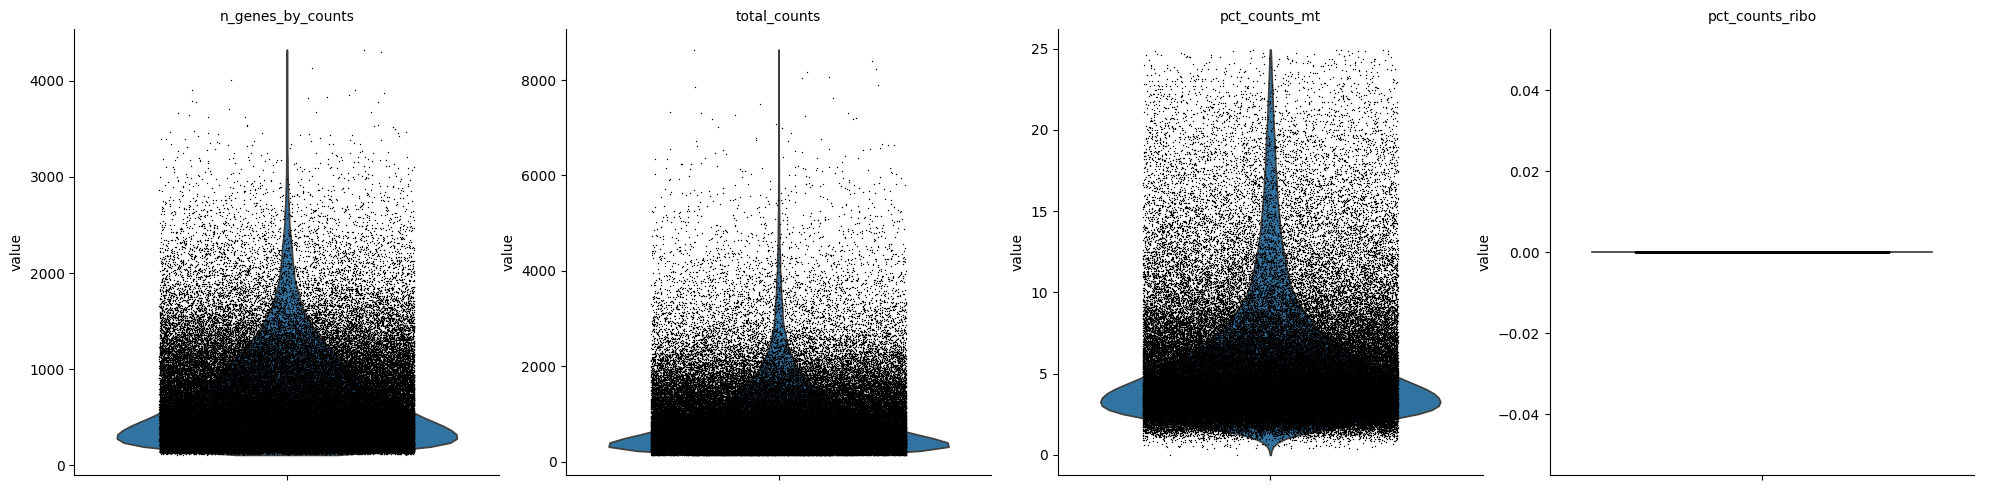

In [ ]:
# 根据百分比设定过滤阈值
low, high = adata.obs['total_counts'].quantile([0.02, 0.98])

手动设置筛选上下限阈值

In [ ]:
# min_counts: 过滤掉总 UMI 计数（测序深度）低于 min_counts 的 Spot
# max_counts: 过滤掉总 UMI 计数高于 max_counts 的 Spot

min_counts = max(100, int(low))
max_counts = max(int(high), 30000)
print(f"Using min_counts={min_counts}, max_counts={max_counts}")

In [ ]:
# --- 1. 基于总 UMI 计数（测序深度）过滤 Spot ---

sc.pp.filter_cells(adata, min_counts=min_counts)
sc.pp.filter_cells(adata, max_counts=max_counts)

# --- 2. 基于生物学指标过滤 Spot（自定义阈值）---

# 检查是否存在线粒体百分比指标（pct_counts_mt）
if 'pct_counts_mt' in adata.obs:
    # 过滤掉线粒体基因计数百分比（mt%）高于 25% 的 Spot。
    adata = adata[adata.obs['pct_counts_mt'] < 25].copy()
    
# 检查是否存在核糖体百分比指标（pct_counts_ribo）
if 'pct_counts_ribo' in adata.obs:
    # 过滤掉核糖体基因计数百分比（ribo%）高于 30% 的 Spot。
    adata = adata[adata.obs['pct_counts_ribo'] < 30].copy()

# --- 3. 过滤低表达基因 ---

# 过滤掉在少于 10 个 Spot（细胞）中表达的基因。
# 移除这些极少表达的基因可以显著降低数据维度，减少计算负担，并提高统计显著性
sc.pp.filter_genes(adata, min_counts=10)

# --- 4. 重新计算 QC 指标（用于验证）---

# 重新标记过滤后的基因列表中的线粒体和核糖体基因
adata.var["mt"]  = adata.var_names.str.startswith(("mt-","mt."))
adata.var["ribo"] = adata.var_names.str.match(r"^(Rps|Rpl)\d", na=False)

# 重新计算过滤后的 Spot 的各项 QC 统计指标
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt","ribo"], inplace=True)

# --- 5. 输出结果与可视化验证 ---

# 打印过滤后剩余的 Spot 和基因数量
print("Remaining spots:", adata.n_obs, "| genes:", adata.n_vars)

# 准备 QC 指标列表，确保这些指标列在 adata.obs 中存在
qc_keys = [k for k in ["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo"] if k in adata.obs.columns]

# 绘制小提琴图，验证过滤效果（过滤后分布应更集中）
if adata.n_obs > 0 and qc_keys:
    # sc.pl.violin：绘制小提琴图，展示过滤后 QC 指标的分布情况
    # jitter=0.3：散点图中的点添加少量随机扰动
    # multi_panel=True：将多个小提琴图放在一个图中展示
    sc.pl.violin(adata, qc_keys, jitter=0.3, multi_panel=True)
else:
    # 如果过滤后没有 Spot 或 QC 关键指标缺失，则跳过绘图
    print("⚠️ Skipping violin plot: no spots or missing QC keys.")

筛选后的空间表达矩阵是 96714 × 17241

📝 Notes:

- 使用前后百分之 2/99 去筛选过高和过低表达的spot
- 线粒体比例 25% & 核糖体比例 30%.
- 删除仅在10个spot中表达的基因
- 重新计算质控指标与作图

--------------------------------------------------------------------------

## 4. 归一化🔎

“归一化” (Normalization) 是空间转录组（单细胞转录组）数据分析流程中一个至关重要的预处理步骤

在 Visium 空间转录组（以及传统的单细胞 RNA 测序）实验中，原始的基因表达计数数据（存储在 adata.X 中）存在显著的技术差异，主要体现在：

- 测序深度差异（Depth/Size Factor）：不同的空间点 (Spot) 由于实验或捕获效率的差异，其捕获到的总 mRNA 分子数量（即总计数，total_counts）可能存在巨大差异。一个 Spot 的总计数高可能只是因为测序深，并不意味着该 Spot 的基因表达水平在生物学上更高。

- 点/细胞大小差异：Visium Spot 捕获的是一个区域内的多个细胞的转录本。不同 Spot 捕获的细胞数量、细胞类型混合物或细胞大小可能不同，这也会导致总计数的差异。

### 4.1 移位对数法（lognormalize）

$$\text{Normalized Count}_{g, i} = \frac{\text{Raw Count}_{g, i}}{\sum_{g'} \text{Raw Count}_{g', i}} \times \text{Target Sum}$$

**操作原理：**

1.  **计算比例因子**：对于每一个 Spot，计算其**所有基因的总计数**（即 `total_counts`）。
2.  **缩放**：将该 Spot 中**每个基因的计数**除以该 Spot 的**总计数**。
3.  **目标和** (`target_sum`)：将缩放后的值乘以一个预设的**目标总和**（例如 $10^4$ 或 $10^6$，后者称为 CPM：Counts Per Million）。这个目标总和确保归一化后，所有 Spot 的总计数都相同（例如都等于 $10^4$ 或 $10^6$），从而消除了测序深度带来的影响。


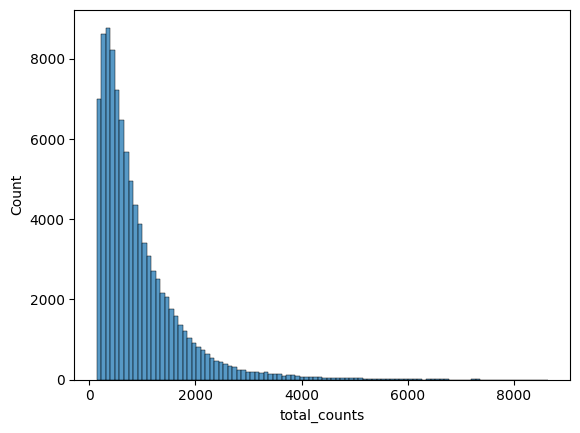

In [ ]:
# 绘制总 UMI 计数的直方图，查看原始分布
sns.histplot(adata.obs["total_counts"], bins=100, kde=False)
plt.show()

In [ ]:
# --- 总计数标准化 (Normalization) ---
# sc.pp.normalize_total：按每个 Spot（细胞）的总 UMI 计数（测序深度）进行标准化。
# adata：输入的 AnnData 对象。
# target_sum=None：如果设置为 None，则函数默认将每个 Spot 的总计数（total_counts）缩放为 1.0e4 (10,000)。
# inplace=False：表示标准化结果（缩放后的计数矩阵）不直接写入 adata.X，而是作为函数的返回值。
scales_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)

# 注意：scales_counts 是一个字典，其中 'X' 键包含了标准化的稀疏矩阵。

# 结果存储在 adata.layers["log1p_norm"] 中，作为 AnnData 对象的备用层 (layer)。
adata.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

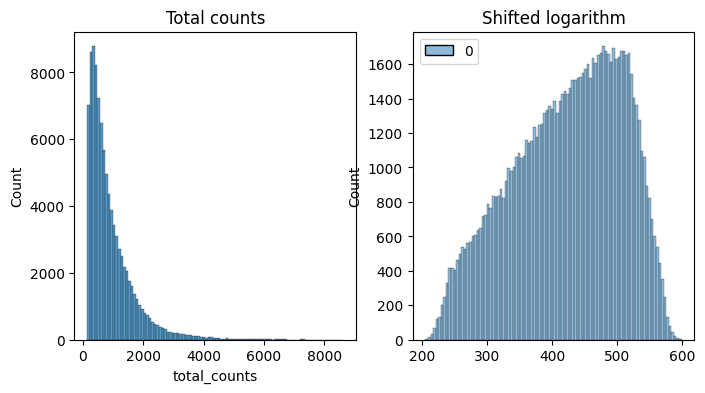

In [ ]:
# 比较标准化前后的总计数分布
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
# 绘制标准化前的总计数分布
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
# 绘制标准化后的总计数分布
p2 = sns.histplot(adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

转换后的数据分布整体形态会更接近正态分布（Normal Distribution）或更对称的钟形，但主要特征是集中性，原本巨大的测序深度差异被消除，数据方差被稳定，使 Spot 间不再因为技术深度不同而产生系统性偏差

### 4.2 pearson残差法

Pearson 残差法，通常通过 `scanpy.pp.normalize_pearson_residuals` 实现，是一种基于**正则化负二项式回归模型（Regularized Negative Binomial Regression）**的归一化技术，旨在稳健地移除数据的技术噪声和稳定方差。

核心思想：

传统的归一化方法仅通过比例缩放移除总计数差异，而 Pearson 残差法更进一步，它**显式地**将每个 Spot 的**总计数（测序深度）作为协变量**纳入回归模型中进行建模，从而将技术变异从生物学信号中分离出来。

操作原理：

1.  **建立回归模型**：为每个基因拟合一个正则化负二项式模型，利用 Spot 的总计数来预测该基因的期望表达量（$\mu$）。
2.  **计算残差**：计算原始观测计数与模型预测的期望计数之间的**标准化残差**。

**残差公式：**
$$\text{Pearson Residual}_{g, i} = \frac{\text{Observed Count}_{g, i} - \mu_{g, i}}{\sqrt{\sigma^2_{g, i}}}$$

* $\text{Observed Count}_{g, i}$：基因 $g$ 在 Spot $i$ 的原始计数。
* $\mu_{g, i}$：模型预测的期望计数。
* $\sigma^2_{g, i}$：模型预测的期望方差。

结果解读：

* **正残差**：表示基因 $g$ 在 Spot $i$ 的表达量**高于**仅由测序深度解释的期望值，通常代表有意义的生物学信号。
* **负残差**：表示表达量**低于**期望值。
* **残差接近零**：表示表达量符合技术噪声模型。

主要优势：

* **稳定方差**：解决了高表达基因方差过大、低表达基因方差过小的问题，使数据更适合后续的线性分析（如 PCA）。
* **无需对数转换**：残差值本身具有近似正态分布的特性，通常无需再进行 $\text{log}(x+1)$ 转换。
* **鲁棒性高**：被认为比简单的总计数缩放能更彻底地消除测序深度的技术偏差。：被认为比简单的总计数缩放能更彻底地消除测序深度的技术偏差。鲁棒性高**：被认为比简单的总计数缩放能更彻底地消除测序深度的技术偏差。

In [ ]:
from scipy.sparse import csr_matrix
# 导入 scipy.sparse 库中的 csr_matrix，用于处理稀疏矩阵数据，提高内存和计算效率。

# --- 计算 Pearson 残差 ---
# sc.experimental.pp.normalize_pearson_residuals：这是 Scanpy 实验性模块中的函数，用于执行 Pearson 残差标准化。
# 该方法基于一个零膨胀负二项式 (ZINB) 或负二项式 (NB) 模型来建模 count data，然后计算每个基因表达值与模型预测值之间的残差。
# 目的：消除细胞特异性的技术因素（如测序深度/总计数）的影响，同时稳定方差。

analytic_pearson = sc.experimental.pp.normalize_pearson_residuals(adata, inplace=False)

# --- 存储残差矩阵 ---
# adata.layers["analytic_pearson_residuals"]：将处理后的残差矩阵存储在 AnnData 对象的备用层中

adata.layers["analytic_pearson_residuals"] = csr_matrix(analytic_pearson["X"])

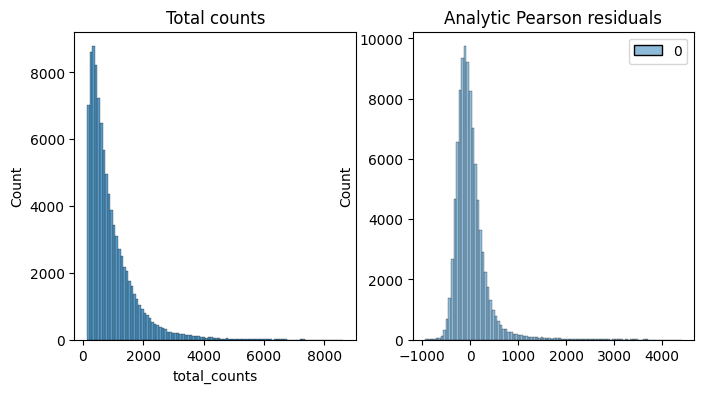

In [ ]:
# 比较转换前后的总计数分布
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
# 绘制转换前的总集数分布
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
# 绘制转换后的总集数分布
p2 = sns.histplot(adata.layers["analytic_pearson_residuals"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Analytic Pearson residuals")
plt.show()

### 4.3 Pearson 残差标准化对比 $\log_{1p}$ 标准化

Pearson 残差标准化（Pearson Residuals Normalization）是一种先进的预处理技术，被认为是优于传统的 $\text{log}(1+x)$（即 $\log_{1p}$ 转换）方法的方差稳定和去噪方案。两者虽然都旨在消除技术偏差和稳定方差，但在执行机制上有本质区别：

1.  **解析性地移除技术噪声：** Pearson 残差方法首先使用**统计模型**（如负二项式模型）来建模计数数据，并将每个 Spot 的**总 UMI 计数（测序深度）**作为协变量。通过计算**观测值与模型预测值之间的残差**，它能够**解析性地**将测序深度带来的系统性技术差异从数据中剥离，使得残差矩阵主要反映真实的**生物学变异**。相比之下，$\log_{1p}$ 转换仅通过缩放和非线性变换来减轻技术差异，无法明确分离噪声。

2.  **更优异的方差稳定：** 传统的 $\log_{1p}$ 转换虽然能压缩高表达值，但不能**均匀地稳定所有表达水平下的方差**。而 Pearson 残差通过将残差**标准化**，能够消除方差与基因平均表达水平之间的正相关关系，实现**全局的方差稳定**，这对于下游的降维（如 PCA）和差异分析至关重要。

3.  **避免 Log 转换的偏差：** $\log_{1p}$ 是一种启发式转换，并不基于数据的生成过程，可能对低表达值过度放大。Pearson 残差则基于数据的**统计生成模型**，能更自然地处理 Count Data 的特性（如零膨胀），避免了 Log 转换可能引入的系统性偏差。

**总结：** Pearson 残差标准化提供了一种**基于统计模型的、方差稳定且专注于生物学信号提取**的预处理方法，是当前进行深度分析和精确建模的**更优选择**，但考虑到实际运行 $\log_{1p}$ 标准化资源消耗低，操作简单，可以视具体情况采用标准化方法

In [ ]:
# 将原始计数矩阵保存到 adata.layers['raw_counts'] 中，作为备用层
adata.layers['raw_counts']=adata.X.copy()

In [ ]:
# 使用log_{1p}标准化
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

## 5. 特征选择🔬（选择高变基因）

我们从测序中获得了包含 **17,241 个基因**的表达矩阵，远超一个 Spot/细胞的实际活跃表达基因数（通常约为 3,000 个）。这种巨大的差异表明矩阵中存在大量**不具分析意义的基因**，它们会严重影响下游分析的效率和准确性。这些无效基因主要包括：在绝大多数 Spot/细胞中都为**零计数（Drop-out）**的低信息量基因，以及在所有细胞中都**普遍高表达**、缺乏生物学变异的看家基因。因此，在预处理环节中，我们必须计算并提取 **高可变基因 (HVGs)**。HVGs 是在不同 Spot/细胞之间表现出**显著表达差异**的核心基因集，它们的作用是：**集中数据中的生物学信号**，确保我们关注于区分细胞类型和状态的关键变异；同时，将基因数量从数万个降至几千个，**显著提高下游建模和生物学检测的计算效率和鲁棒性**。

### 5.1 基于基因离散度

In [ ]:
# --- 基于基因表达离散度选择高度可变的基因 (HVGs) ---

adata_dis_num = sc.pp.highly_variable_genes(
    adata,  # 输入的 AnnData 对象，包含经过标准化的数据
    # flavor="seurat"：指定 HVG 选择算法的风格。
    # "seurat" 基于基因的平均表达量和方差（离散度）来选择 HVGs。
    flavor="seurat",
    
    # n_top_genes=3000：设定要选择的 HVGs 的数量。
    # 这里将基因数从完整的基因集（例如 17,000+）缩减到最重要的 3000 个。
    n_top_genes=3000,

    # subset=False：表示函数不会直接过滤 adata.X 矩阵，而是将 HVG 的选择结果（布尔列）
    # 添加到返回的 AnnData 对象的 .var 属性中。
    subset=False,

    # inplace=False：表示不直接修改原始的 adata 对象。
    # 函数将返回一个新的 AnnData 对象或包含 HVG 信息的 DataFrame（取决于 Scanpy 版本和参数设置）。
    inplace=False,
)

# 注意：函数的返回值 adata_dis_num（通常是一个包含 .var 信息的 DataFrame）
# 将用于后续的实际过滤操作。

In [153]:
adata_dis_num

,means,dispersions,mean_bin,dispersions_norm,highly_variable
Xkr4,0.033484,0.062554,"(-0.00203, 0.103]",-0.958972,False
Rp1,0.000194,0.789893,"(-0.00203, 0.103]",2.316010,True
Sox17,0.008532,0.555668,"(-0.00203, 0.103]",1.261370,True
Lypla1,0.016001,0.185817,"(-0.00203, 0.103]",-0.403956,False
Tcea1,0.088683,0.203346,"(-0.00203, 0.103]",-0.325028,False
...,...,...,...,...,...
mt-Nd4,1.021672,0.913202,"(0.928, 1.032]",0.058368,False
mt-Nd5,1.047447,0.851016,"(1.032, 1.135]",-0.639082,False
mt-Nd6,0.233993,0.644393,"(0.206, 0.31]",1.267288,True
mt-Cytb,1.579774,1.134591,"(1.547, 1.651]",-0.707107,False


### 5.2 基于归一化方差

In [ ]:
# --- 基于 Seurat V3 风格的归一化选择高度可变的基因 (HVGs) ---

adata_var_num = sc.pp.highly_variable_genes(
    adata, 
    # flavor="seurat_v3"：指定 HVG 选择算法的风格。
    # Seurat V3 风格是专门为 UMI 计数数据设计的，它在选择 HVGs 之前，
    # 会对数据应用一个稳定方差的归一化过程（类似于 SCTransform 的逻辑）
    flavor="seurat_v3",

    # layer='raw_counts'：指定函数应使用哪个 AnnData 层（layer）作为原始输入计数。
    # 注意：这个参数是 Seurat V3 风格的关键，它要求使用原始的、未经处理的计数数据。
    # 这里的 'raw_counts' 假设是你之前存储原始计数数据的层名。
    layer='raw_counts',

    # n_top_genes=3000：设定要选择的 HVGs 的数量。
    # 这里选择最具信息量的 3000 个基因。
    n_top_genes=3000,

    # subset=False：表示函数不会直接过滤 adata.X 矩阵。
    # 而是将 HVG 的选择结果（一个包含布尔值的列 'highly_variable'）添加到返回对象的 .var 属性中。
    subset=False,

    # inplace=False：表示不直接修改原始的 adata 对象。
    # 函数返回一个新的 AnnData 对象或包含 HVG 信息的 DataFrame，便于后续操作。
    inplace=False,
)

# 注意：adata_var_num 将包含一个 .var 属性，其中有一个布尔列标记了哪些基因被选为 HVG。

adata_var_num

,means,variances,gene_name,highly_variable_rank,variances_norm,highly_variable
Xkr4,0.054315,0.061043,Xkr4,NaN,1.014452,False
Rp1,0.000145,0.000165,Rp1,1222.0,1.108604,True
Sox17,0.008013,0.009624,Sox17,1189.0,1.110404,True
Lypla1,0.022065,0.022757,Lypla1,NaN,0.956656,False
Tcea1,0.129929,0.146592,Tcea1,NaN,0.939471,False
...,...,...,...,...,...,...
mt-Nd4,1.773084,2.908834,mt-Nd4,NaN,0.595378,False
mt-Nd5,1.920105,3.471339,mt-Nd5,NaN,0.632337,False
mt-Nd6,0.241919,0.262207,mt-Nd6,NaN,0.807508,False
mt-Cytb,3.897057,9.076165,mt-Cytb,NaN,0.572234,False


### 5.3 基于pearson近似残差

In [ ]:
# --- 基于皮尔逊残差计算高可变基因 (HVGs) ---

adata_pearson_num = sc.experimental.pp.highly_variable_genes(
    adata,  
    # flavor="pearson_residuals"：指定 HVG 选择算法为皮尔逊残差方法
    # 该方法基于统计模型（通常是负二项式模型）计算残差，然后选择残差最高的基因作为 HVGs
    # 目的：确保 HVG 的变异是生物学原因，而非测序深度等技术因素
    flavor="pearson_residuals",

    # layer='raw_counts'：指定函数应使用哪个 AnnData 层作为原始输入计数
    # 注意：皮尔逊残差方法必须使用原始的、未标准化的计数数据进行建模
    layer='raw_counts',

    # n_top_genes=3000：设定要选择的 HVGs 的数量
    # 目标是从完整的基因集中识别出 3000 个最具生物学变异的基因
    n_top_genes=3000,

    # subset=False：表示函数不会直接修改或过滤 adata.X 矩阵
    # 而是将 HVG 的选择结果（一个包含布尔值的列 'highly_variable'）添加到返回对象的 .var 属性中
    subset=False,

    # inplace=False：表示不直接修改原始的 adata 对象
    # 函数返回一个包含 HVG 信息的 AnnData 对象（或 DataFrame），便于后续操作
    inplace=False,
)

# 注意：adata_pearson_num 将包含一个 .var 属性，其中标记了被选为 HVG 的基因。
# 在后续的分析中，应使用这个列表来过滤数据

adata_pearson_num

,means,variances,residual_variances,highly_variable_rank,highly_variable
Xkr4,0.054315,0.061043,0.883427,NaN,False
Rp1,0.000145,0.000165,1.945314,256.0,True
Sox17,0.008013,0.009624,1.641043,789.0,True
Lypla1,0.022065,0.022757,0.999786,NaN,False
Tcea1,0.129929,0.146592,0.983424,NaN,False
...,...,...,...,...,...
mt-Nd4,1.773084,2.908834,2.073837,174.0,True
mt-Nd5,1.920105,3.471339,1.964481,236.0,True
mt-Nd6,0.241919,0.262207,1.623414,847.0,True
mt-Cytb,3.897057,9.076165,2.620214,61.0,True


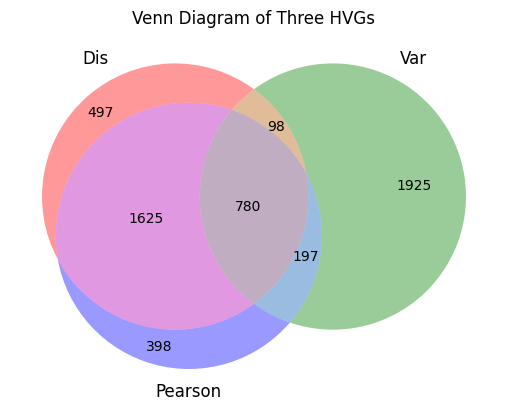

In [ ]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn3 # 导入专门用于绘制三集合维恩图的库

# --- 准备三个 HVG 集合 ---

# 集合 1: 基于基因表达离散度（Dis/Seurat 风格）选择的 HVGs
# .loc[...]：从 adata_dis_num 的 .var 中筛选出 'highly_variable' 为 True 的基因
# .index.tolist()：提取这些基因的名称（索引）并转换为列表
# set(...)：将列表转换为集合（set），以便进行集合运算
list1 = set(adata_dis_num.loc[adata_dis_num['highly_variable']==True].index.tolist())

# 集合 2: 基于基因归一化（Var/Seurat V3 风格）选择的 HVGs
list2 = set(adata_var_num.loc[adata_var_num['highly_variable']==True].index.tolist())

# 集合 3: 基于皮尔逊残差（Pearson Residuals）选择的 HVGs
list3 = set(adata_pearson_num.loc[adata_pearson_num['highly_variable']==True].index.tolist())

# --- 绘制维恩图 ---

# venn3：绘制三个集合的维恩图。
# [list1, list2, list3]：输入三个集合。
# set_labels=('Dis', 'Var', 'Pearson')：设置三个圆圈（集合）的标签，便于识别。
venn = venn3([list1, list2, list3], set_labels=('Dis', 'Var', 'Pearson'))

# 添加标题
plt.title("Venn Diagram of Three HVGs")

# 显示绘制好的图形
plt.show()

### 5.4 HVG 选择方法的重叠与差异分析

观察到**离散度 (`Dis`)** 和 **Pearson 残差 (`Pearson`)** 两种方法选择的基因集合有较高的重复性，而与 **Seurat V3 风格 (`Var`)** 的差异相对较大，这揭示了它们在处理数据噪声时的根本区别。离散度方法和 Pearson 残差法都专注于寻找**脱离技术背景噪声**、表现出**强烈变异性**的生物学信号，因此它们容易共同识别出驱动核心细胞异质性的基因。然而，**Pearson 残差法**通过统计模型**精确地解析并移除了**测序深度带来的方差贡献，从而提供的是**最纯粹的生物学残差变异信号**。相比之下，Seurat V3 风格使用了另一种复杂的方差稳定归一化方法，其稳定效果和关注点有所不同，导致其选择的基因集合会偏向于某些在特定尺度下变异大的中低表达基因，因此与前两种方法产生的基因集合有较大的差异。最终，选择 Pearson 残差法可以确保我们聚焦于那些**变异性最不受技术因素干扰**的基因，以提高下游分析的准确性。

我们发现三种不同方法所找到的高可变基因（HVGs）仅有955个是相同的，这意味着不同的方法所寻找到的高可变基因可能会影响你的下游分析的误差

In [ ]:
# 我们选择了 Pearson 残差法来选择高变基因
sc.experimental.pp.highly_variable_genes(
    adata, 
    flavor="pearson_residuals",
    layer='raw_counts',
    n_top_genes=3000,
    subset=False,
    inplace=True,
)

In [158]:
adata.var.head()

,gene_ids,feature_types,genome,mt,ribo,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_counts,means,variances,residual_variances,highly_variable_rank,highly_variable
Xkr4,ENSMUSG00000051951,Gene Expression,mm10,False,False,4830,0.054315,0.052891,95.005894,5253.0,8.566745,5253.0,0.054315,0.061043,0.883427,NaN,False
Rp1,ENSMUSG00000025900,Gene Expression,mm10,False,False,13,0.000145,0.000145,99.986558,14.0,2.708050,14.0,0.000145,0.000165,1.945314,256.0,True
Sox17,ENSMUSG00000025902,Gene Expression,mm10,False,False,704,0.008013,0.007981,99.272081,775.0,6.654152,775.0,0.008013,0.009624,1.641043,789.0,True
Lypla1,ENSMUSG00000025903,Gene Expression,mm10,False,False,2078,0.022065,0.021825,97.851397,2134.0,7.666222,2134.0,0.022065,0.022757,0.999786,NaN,False
Tcea1,ENSMUSG00000033813,Gene Expression,mm10,False,False,11135,0.129929,0.122155,88.486672,12566.0,9.438829,12566.0,0.129929,0.146592,0.983424,NaN,False


### 5.5 基于空间变异度选择高度可变的基因

#### 莫兰系数 (Moran's I) 介绍

**莫兰系数（Moran's I）**是空间统计学中用于度量**空间自相关性（Spatial Autocorrelation）**的关键指标，在空间转录组分析中用于识别 **高空间变异基因（SVGs）**。它衡量的是某个基因的表达量与其在**邻近 Spot** 中的表达量之间的相关性。莫兰系数的取值范围通常在 **-1 到 +1** 之间：接近 **+1** 表明该基因的表达在空间上呈**聚集（高值被高值包围）**模式，通常指示组织中的**特定细胞团块或微环境**；接近 **0** 表明基因表达是**随机分布**的；接近 **-1** 则表明是**分散或交替（棋盘）**模式。通过计算每个基因的莫兰系数并进行置换检验（如你代码中的 `n_perms=200`），我们能够筛选出那些具有**统计显著非随机空间模式**的基因，将分析聚焦于真正受空间位置影响的生物学信号

In [ ]:
# --- 基于空间变异度选择高度可变的基因（SVGs） ---

# 设定子样本的比例（例如：15%）
sample_frac = 0.15

# 从原始 AnnData 对象 (adata) 中随机抽取 15% 的 Spot/观测值，创建一个子样本对象 (adata_sub)
adata_sub = adata[adata.obs.sample(frac=sample_frac, random_state=1).index].copy()

# 构建空间邻居图（定义哪些 Spot 彼此相邻）
# sq.gr.spatial_neighbors：这是 Squidpy 库用于建立空间邻接矩阵的函数
# coord_type='generic'：指定使用 AnnData.obsm['spatial'] 中的坐标信息来构建邻居图
# 结果存储在 adata_sub.obsp 和 adata_sub.uns 中
sq.gr.spatial_neighbors(adata_sub, coord_type='generic')  # 视 coord 类型

# 计算空间自相关性（莫兰系数）
# sq.gr.spatial_autocorr：计算空间自相关性的函数。
# mode='moran'：指定使用莫兰系数 (Moran's I) 来量化空间自相关性。
# n_perms=200：指定进行 200 次置换检验，以计算每个基因的 P 值，用于判断空间自相关是否具有统计显著性
# 结果存储在 adata_sub.uns['moranI'] 中
sq.gr.spatial_autocorr(adata_sub, mode='moran', n_perms=200)

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/metrics/_morans_i.py:105: UserWarning: 67 variables were constant, will return nan for these.
  return _MoransI(graph, vals)()
100%|██████████| 200/200 [00:39<00:00,  5.10/s]


In [ ]:
# 查看空间变异度较高的基因（SVGs）
# 根据莫兰系数 (Moran's I) 对基因进行排序，选择
svg = adata_sub.uns['moranI']['I'].sort_values(ascending=False).head(1000).index.tolist()
print(f"Top 10 SVGs: {svg[:10]}")

Top 10 SVGs: ['Ttr', 'Mbp', 'Pcp4', 'Mobp', 'Penk', 'Plp1', 'Prkcd', 'Camk2n1', 'Nrgn', 'Camk2a']


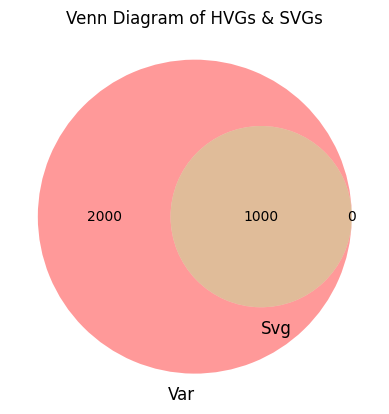

In [ ]:
# 比较 HVGs 和 SVGs 的重叠情况
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
# 绘制 Venn 图
svg = set(svg)
venn = venn2([list3, svg], set_labels=('Var', 'Svg'))

# 显示图形
plt.title("Venn Diagram of HVGs & SVGs")
plt.show()

发现通过莫兰系数计算出的所有空间变异基因 (SVGs) 都包含在非空间方法（如 Pearson 残差或 Seurat V3 风格）筛选出的高可变基因 (HVGs) 集合内。这表明：SVG 集合是 HVG 集合的一个子集。从生物学上讲，任何在空间上表现出非随机模式（即具有空间变异性）的基因，必然也是在整个组织中表现出高表达差异的基因。这一结果有力地验证了之前 HVG 筛选步骤的有效性，确认该步骤成功地捕获了所有潜在的生物学信号。因此，可以放心地将 HVGs 视为包含了所有细胞异质性和所有空间结构信号的超集，并进一步使用 SVGs 集合来精确地聚焦于与组织微环境和空间位置强相关的基因集进行深入分析

In [162]:
#我们首先选择高可变基因，并将原数据存放在.raw中
adata_raw = adata.copy()

In [163]:
adata=adata[:,adata.var['highly_variable']==True]
adata.shape

(96714, 3000)

## 6. 降维

### 6.1 PCA

--- 数据缩放 (Scaling) ---

缩放过程：
- 1. 均值中心化：将每个基因的平均表达值移至零（减去该基因的平均值）
- 2. 方差归一化：将每个基因的方差调整为单位方差（除以该基因的标准差）
max_value=3：设定缩放后的数据值的最大绝对值
作用：限制缩放后矩阵中的极端高值（离群值），大于 3 的值将被设置为 3；任何小于 -3 的值将被设置为 -3，防止极少数离群值（通常由技术噪声或生物学上的超高表达引起）在降维分析（如 PCA）中占据过大的权重，从而扭曲主成分

In [ ]:
sc.pp.scale(adata, max_value=3)

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/preprocessing/_scale.py:309: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


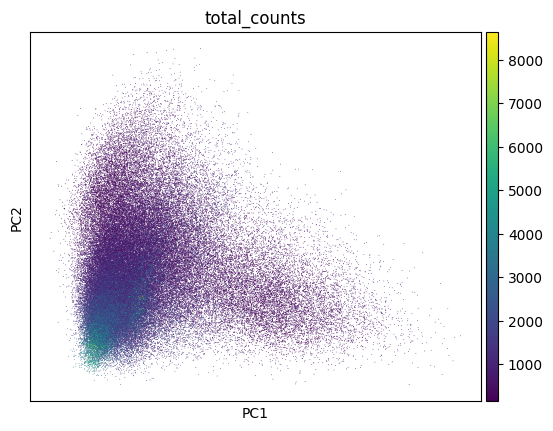

In [165]:
sc.pp.pca(adata, n_comps=50)
sc.pl.pca(adata, color='total_counts')

In [ ]:
# 将未缩放的数据保存为adata1
adata1 = adata_raw.copy()

In [ ]:
# --- 主成分分析 (Principal Component Analysis, PCA) ---

sc.pp.pca(adata, n_comps=50)  # n_comps=50：指定要计算的主成分数量
sc.pp.pca(adata1, n_comps=50)

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/preprocessing/_pca/__init__.py:385: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca


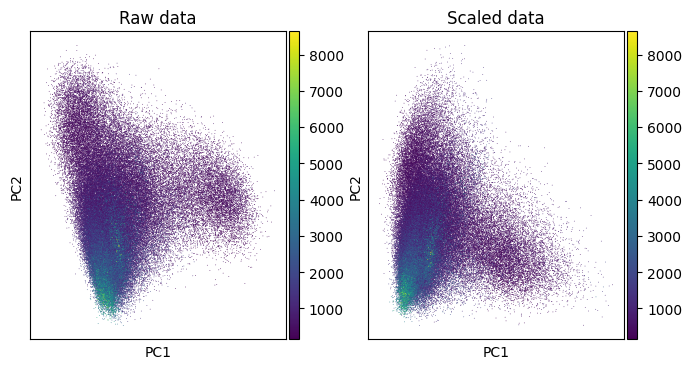

In [ ]:
# --- PCA 结果可视化 ---
# 绘制 PCA 结果的二维散点图（默认是 PC1 vs PC2）
# 目的：直观地检查 Spot（观测值）在主成分空间中的分布和聚类趋势

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
p1 = sc.pl.pca(adata1,color='total_counts',ax=axes[0],show=False)
axes[0].set_title("Raw data")
p2 = sc.pl.pca(adata,color='total_counts',ax=axes[1],show=False)
axes[1].set_title("Scaled data")
plt.show()

左图展示的是原始数据（未进行方差归一化）的 PCA 结果，其分布可能被少数具有极端方差的基因或总计数极高的 Spot所扭曲，Spot 的颜色（测序深度）往往会在 PC 空间中出现聚集，表明技术偏差是主要的驱动力。右图展示的是经过 sc.pp.scale(max_value=3) 缩放后的数据，由于缩放过程确保了所有基因的方差贡献公平且消除了极端值的影响，Spot 的分布将更均匀、更分散，并且颜色（total_counts）会随机混合

In [ ]:
# 保存和读取 AnnData 对象
# 这里我们将处理后的数据保存为 'adata_processed.h5ad'，以便后续分析使用
# 同时保存未缩放的原始数据为 'adata_processed_raw.h5ad'
adata.write('/data/05_basis/data/adata_processed.h5ad')
adata1.write('/data/05_basis/data/adata_processed_raw.h5ad')

In [ ]:
adata = sc.read_h5ad('/data/05_basis/data/adata_processed.h5ad')
adata1 = sc.read_h5ad('/data/05_basis/data/adata_processed_raw.h5ad')

### 6.2 t-SNE

t-SNE 是一种基于图的、非线性的降维技术，它将高维数据投影到 2D 或 3D 组件上。该方法基于数据点之间的高维欧几里得距离定义了一个高斯概率分布。随后，使用 t 分布在低维空间中重建概率分布，其中嵌入通过梯度下降进行优化

In [ ]:
# adata：输入的 AnnData 对象。t-SNE 默认会使用 adata.obsm['X_pca']（PCA 结果）作为输入。
# 结果：t-SNE 的坐标（通常为二维）将存储在 adata.obsm['X_tsne'] 中。
sc.tl.tsne(adata)
sc.tl.tsne(adata1)

OpenBLAS warning: precompiled NUM_THREADS exceeded, adding auxiliary array for thread metadata.
To avoid this warning, please rebuild your copy of OpenBLAS with a larger NUM_THREADS setting
or set the environment variable OPENBLAS_NUM_THREADS to 64 or lower


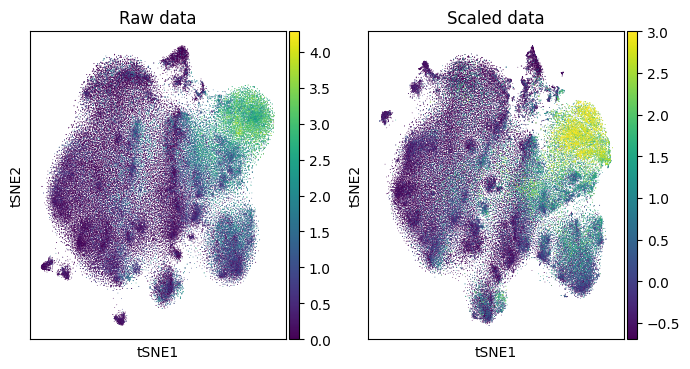

In [ ]:
# --- t-SNE 结果可视化 ---
# 绘制 t-SNE 结果的二维散点图（默认是 PC1 vs PC2）
# 目的：直观地检查 Spot（观测值）在主成分空间中的分布和聚类趋势
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
p1 = sc.pl.tsne(adata1,color='Mbp',ax=axes[0],show=False)  # color='Mbp'：指定用于着色的基因（这里以 Mbp 基因为例）
axes[0].set_title("Raw data")
p2 = sc.pl.tsne(adata,color='Mbp',ax=axes[1],show=False)
axes[1].set_title("Scaled data")
plt.show()

左图展示的是原始数据（Raw data）的 t-SNE 结果，基因 Mbp 的颜色分布可能因少数未被钳制的极端高表达值而被扭曲，导致大部分 Spot 的颜色对比度不足，难以识别 Mbp 的真实表达模式。右图展示的是经过 `sc.pp.scale(max_value=3)` 缩放和钳制后的数据，由于消除了极端值的干扰，Mbp 的表达强度在颜色映射上将更均匀、更平滑。最终结果将证明缩放和钳制操作的有效性，即它使得基因表达差异的生物学信号在 t-SNE 空间中更加清晰且易于解释，有助于研究人员更可靠地识别和定位表达该基因的细胞群

### 6.3 UMAP

UMAP 是一种非线性降维技术，与 t-SNE 类似，主要用于将高维数据（如基因表达矩阵）映射到二维或三维空间进行可视化。它被认为是 t-SNE 的一个更快速、更高效的替代品

无论是 UMAP 还是 t-SNE，它们的核心都是基于数据点之间的相似性或邻近关系来进行降维和可视化的。`sc.pp.neighbors` 就是专门用来计算和定义这种邻近关系的函数

- `sc.pp.neighbors` 的作用： 这个函数计算每个 Spot/细胞与其他所有 Spot/细胞之间的距离，并根据这个距离为每个点确定其 n_neighbors（例如 30 个）最近邻居。它将这种邻近关系存储为一个图结构（Graph），这是 UMAP 算法的直接输入

- UMAP 的输入： UMAP 算法本身并不从头计算距离。它直接接收这个预先构建好的邻域图，并尝试在低维空间中保留这个图的拓扑结构

In [173]:
sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_pca')

In [ ]:
# 计算 UMAP 坐标
sc.tl.umap(adata)

In [ ]:
# 计算adata1的邻居图和UMAP
sc.pp.neighbors(adata1, n_neighbors=30, use_rep='X_pca')
sc.tl.umap(adata1)

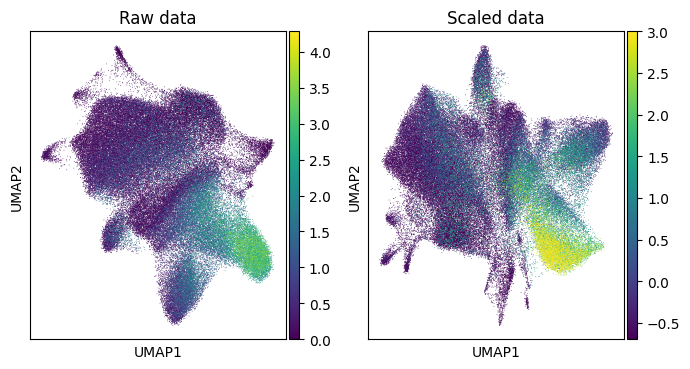

In [ ]:
# --- UMAP 结果可视化 ---
# 绘制 UMAP 结果的二维散点图（默认是 PC1 vs PC2）
# 目的：直观地检查 Spot（观测值）在主成分空间中的分布和聚类趋势
fig, axes = plt.subplots(1, 2, figsize=(8,4))
p1 = sc.pl.umap(adata1,color='Mbp',ax=axes[0],show=False) # color='Mbp'：指定用于着色的基因（这里以 Mbp 基因为例）
axes[0].set_title("Raw data")
p2 = sc.pl.umap(adata,color='Mbp',ax=axes[1],show=False)
axes[1].set_title("Scaled data")
plt.show()

右图（Scaled data）的 UMAP 将提供一个更清晰、更具生物学可解释性的 Mbp 表达分布可视化，因为数据已经过降噪处理，确保了基因表达差异的颜色映射是可靠的

### 6.4 导入已有坐标信息

In [ ]:
# 这里我们直接读取 cluster 已有的clusters信息
clusters = pd.read_csv(
    os.path.join(BIN_DIR, "analysis/clustering/gene_expression_kmeans_10_clusters/clusters.csv"),
    index_col=0  # 用 barcode 作为 index
)

In [180]:
clusters['Cluster']

Barcode
s_016um_00052_00082-1    3
s_016um_00150_00268-1    3
s_016um_00144_00175-1    6
s_016um_00165_00109-1    6
s_016um_00297_00147-1    5
                        ..
s_016um_00109_00223-1    5
s_016um_00039_00175-1    1
s_016um_00037_00193-1    1
s_016um_00144_00329-1    1
s_016um_00176_00108-1    2
Name: Cluster, Length: 98917, dtype: int64

In [181]:
# 确保列名正确，例如 'cluster'
adata.obs['cluster'] = clusters['Cluster'].reindex(adata.obs_names)

In [182]:
adata.obs['cluster']

s_016um_00052_00082-1    3
s_016um_00150_00268-1    3
s_016um_00144_00175-1    6
s_016um_00165_00109-1    6
s_016um_00297_00147-1    5
                        ..
s_016um_00375_00231-1    3
s_016um_00039_00175-1    1
s_016um_00037_00193-1    1
s_016um_00144_00329-1    1
s_016um_00176_00108-1    2
Name: cluster, Length: 96714, dtype: int64

In [ ]:
# 将原始聚类标签的数据类型从数值型（如整数 int 或分类 category）强制转换为字符串型（str）
# 这样可以确保它们被视为离散的、名义上的标签，尤其是在可视化和后续统计分析中
adata.obs["clusters"] = adata.obs["cluster"].astype(str)
adata.obs['clusters'].value_counts

<bound method IndexOpsMixin.value_counts of s_016um_00052_00082-1    3
s_016um_00150_00268-1    3
s_016um_00144_00175-1    6
s_016um_00165_00109-1    6
s_016um_00297_00147-1    5
                        ..
s_016um_00375_00231-1    3
s_016um_00039_00175-1    1
s_016um_00037_00193-1    1
s_016um_00144_00329-1    1
s_016um_00176_00108-1    2
Name: clusters, Length: 96714, dtype: object>

In [184]:
# 读取 UMAP 坐标
umap_coords = pd.read_csv(
    os.path.join(BIN_DIR, "analysis/umap/gene_expression_2_components/projection.csv"),
    index_col=0  # 用 barcode 作为 index
)

In [ ]:
# 根据 adata.obs_names 的顺序重新索引 umap_coords，并将其存储到 adata.obsm['X_umap'] 中
# 这样可以确保 UMAP 坐标与 adata 中的 Spot 顺序一致
adata.obsm['X_umap'] = umap_coords.reindex(adata.obs_names).values

In [186]:
adata

AnnData object with n_obs × n_vars = 96714 × 3000
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_counts', 'cluster', 'clusters'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'means', 'variances', 'residual_variances', 'highly_variable_rank', 'highly_variable', 'mean', 'std'
    uns: 'spatial', 'log1p', 'hvg', 'pca', 'tsne', 'neighbors', 'umap'
    obsm: 'spatial', 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'analytic_pearson_residuals', 'raw_counts'
    obsp: 'distances', 'connect

📝 笔记：

- 归一化将每个点缩放到相同的总表达计数
- 对数变换稳定方差。
- 选择 3000 个高度可变的基因 （HVG）
- PCA 将数据减少到 30 个维度
- 邻近图 + UMAP 可视化数据
- 构建聚类（分辨率 0.8）
- 图显示了 UMAP 上的簇

-----------------------------------------------------

完成 PCA、t-SNE 或 UMAP 等降维步骤后，我们的数据现在已经从数万个基因的高维空间，被有效地压缩到了一个二维或三维的特征空间中。是的，这就标志着进入了数据可视化的关键阶段。

降维的最终目的正是为了可视化，因为高维空间的复杂结构现在得以在平面上直观呈现。在这个低维嵌入空间中，相似的 Spot（或细胞）会聚集在一起，形成清晰的簇群。接下来，我们可以利用这些降维图（如 UMAP 或 t-SNE）来映射和展示基因的表达模式、已知的细胞类型、质量控制指标，以及后续的聚类结果。这一可视化过程是将复杂的数学处理转化为直观的生物学洞察的关键转折点，帮助我们发现数据中隐藏的细胞异质性、识别主要的细胞群体，并验证预处理和降维步骤的有效性。

## 7. 空间基因表达和聚类可视化🎨

我们可以直接在组织上覆盖特定的基因和簇。

### 7.1 基因表达叠加组织切片

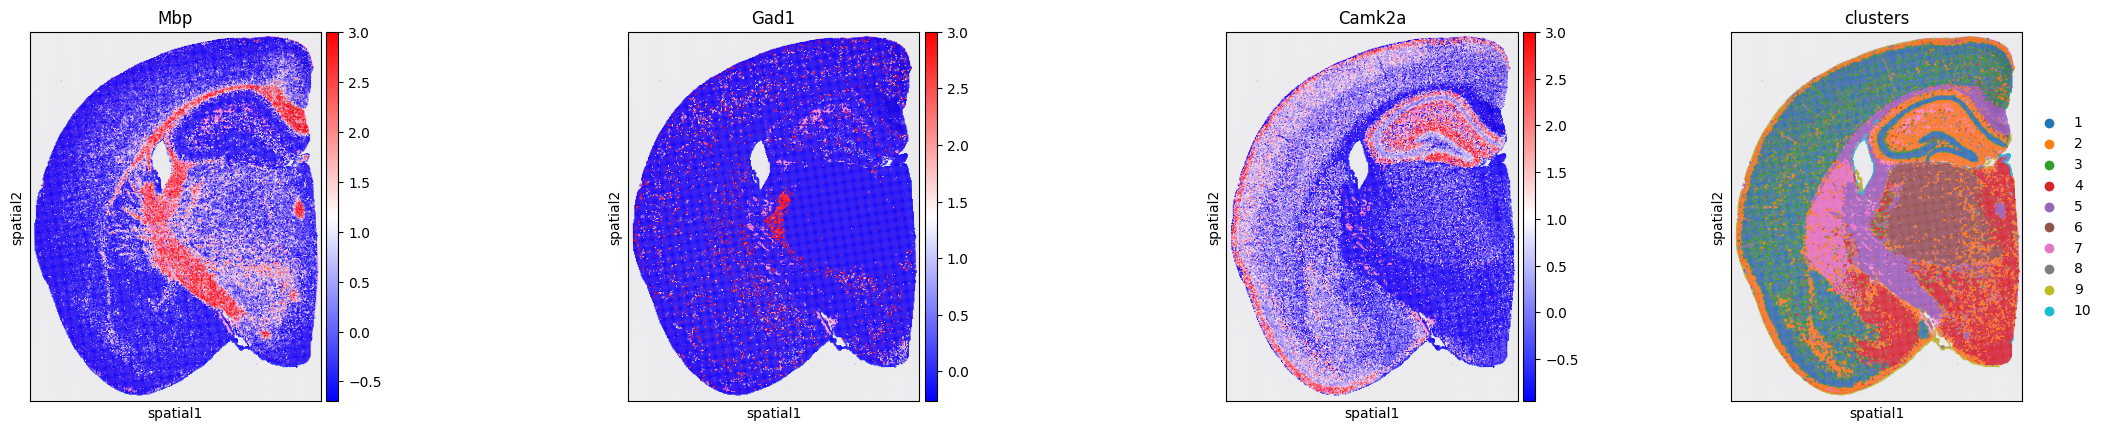

In [ ]:
sq.pl.spatial_scatter(
    adata,  # [必选] 输入的 AnnData 对象，必须包含空间坐标 (adata.obsm['spatial'])
    color=[ # [必选] 着色变量，可以是单个基因或一个列表
        "Mbp",        # 基因：少突胶质细胞标记基因
        "Gad1",       # 基因：抑制性神经元标记基因
        "Camk2a",     # 基因：兴奋性神经元标记基因
        "clusters"    # AnnData.obs 中的列：聚类分配结果
    ],
    library_id=lib_id, # 指定要绘制的组织切片的库 ID
    cmap='bwr',        # 连续变量（基因表达）的颜色映射方案。'bwr' = 蓝-白-红
    size=1.2,          # 散点图中每个 Spot 的半径大小
    palette='Set1',    # 离散变量（如 'clusters'）的颜色调色板 (可选)
    ncols=3,           # 当 'color' 是列表时，指定子图的列数 (可选)
    wspace=0.4,        # 调整多面板图（子图）之间的水平间距 (可选)
    img="hires",       # 指定使用的组织图像分辨率 ('hires' 或 'lowres')
    alpha=0.7,         # 散点的透明度 (0-1 之间)
    size=1.2           # 散点的大小 (可选）
)

### 7.2 基因表达叠加UMAP可视化

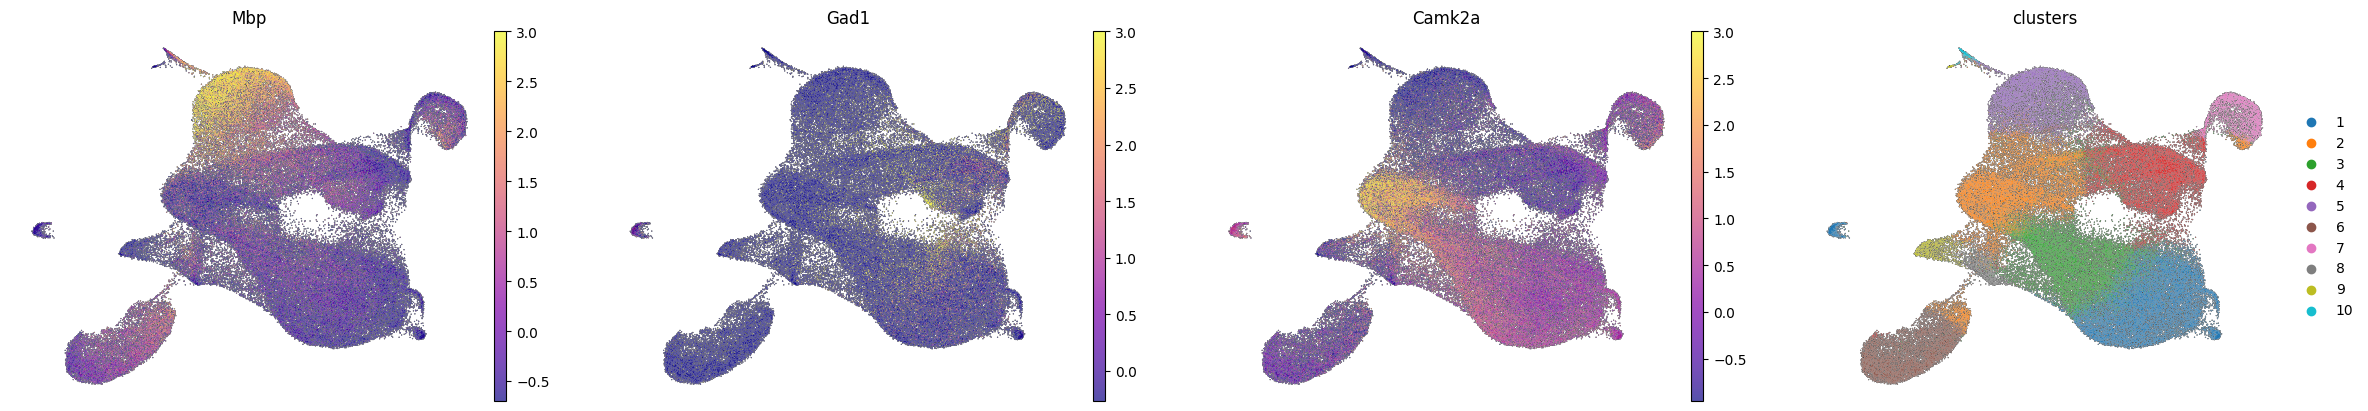

In [ ]:
sc.pl.umap(
    adata,
    color=[
        "Mbp",        # 连续变量：少突胶质细胞标记基因
        "Gad1",       # 连续变量：抑制性神经元标记基因
        "Camk2a",     # 连续变量：兴奋性神经元标记基因
        "clusters"    # 离散变量：聚类分配结果
    ],
    add_outline=True, # 确保在绘制 'clusters' 时，每个簇周围有清晰的轮廓
    frameon=False,    # 移除图表的边框，使图形更美观
    cmap='plasma',    # 对连续变量（基因）使用 'plasma' 配色方案
    size=1.2          # 设置 Spot 的大小
)

In [ ]:
# 保存最终处理好的 AnnData 对象，供后续分析使用
adata.write('/data/05_basis/data/adata_processed.h5ad')

---

## 8. spot的基础注释
### 8.1 寻找差异marker基因🧬

In [ ]:
# 计算差异基因
sc.tl.rank_genes_groups(
    adata, 
    groupby="clusters",     # [必选] 指定分组的列名，即 'adata.obs' 中的聚类结果
    method="wilcoxon"       # [必选] 使用的统计方法。'wilcoxon'（秩和检验）是单细胞/空间转录组分析中最常用的非参数方法
    # 常用可选参数：
    # groups='all',         # 默认：对所有组进行测试。也可指定 ['0', '1']
    # reference='rest',     # 默认：将当前组与所有其他组比较（One-vs-Rest）。也可指定一个特定组作为参考
    # use_raw=True,         # 是否使用 'adata.raw.X' 中的原始计数数据进行计算 (推荐 True, 但需根据数据预处理方式确定)
    # n_genes=25,           # 为每个组保留的差异表达基因数量
    # key_added='markers',  # 存储结果的键名，结果将被存入 'adata.uns[markers]'
)

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: inv

In [ ]:
# --- 提取和排序差异表达基因 (DEGs) ---

# 将 DEGs 结果从 AnnData 转换为 DataFrame。
rg_df = sc.get.rank_genes_groups_df(adata, group=None) \
          # 排序：按聚类 ('group') 分组，然后按校正 P 值 ('pvals_adj') 升序和得分 ('scores') 降序排序。
          .sort_values(["group","pvals_adj","scores"], ascending=[True, True, False])

topN = 5 # 设定每个组要提取的 Top N 基因数量

# 按聚类分组，提取每个组中最显著的 top N 基因。
top_df = rg_df.groupby("group", as_index=False, sort=False).head(topN)

# 生成一个按聚类顺序排列的、不含重复项的最终基因列表。
ordered_genes = top_df.groupby("group")["names"].apply(list).explode().drop_duplicates().tolist()

# 打印最终的标记基因列表。
print(ordered_genes)

['Nrgn', 'Slc17a7', 'Olfm1', 'Ptk2b', 'Snap25', 'mt-Co2', 'mt-Co1', 'mt-Atp6', 'mt-Co3', 'mt-Cytb', 'Camk2n1', 'Camk2a', 'Nap1l5', 'Hap1', 'Scg2', 'Snhg11', 'Uchl1', 'Mbp', 'Plp1', 'Mobp', 'Fth1', 'Trf', 'Pcp4', 'Prkcd', 'Rora', 'Atp2a2', 'Penk', 'Ppp1r1b', 'Arpp21', 'Rasd2', 'Apod', 'Igfbp7', 'Epas1', 'Ahnak', 'Ptprb', 'Ptgds', 'Atp1a2', 'Apoe', 'Igf2', 'Ccdc153', 'Pltp', 'Tm4sf1']


/tmp/ipykernel_3430648/741887739.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_df = rg_df.groupby("group", as_index=False, sort=False).head(topN)
/tmp/ipykernel_3430648/741887739.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ordered_genes = top_df.groupby("group")["names"].apply(list).explode().drop_duplicates().tolist()


### 8.2 差异基因气泡图

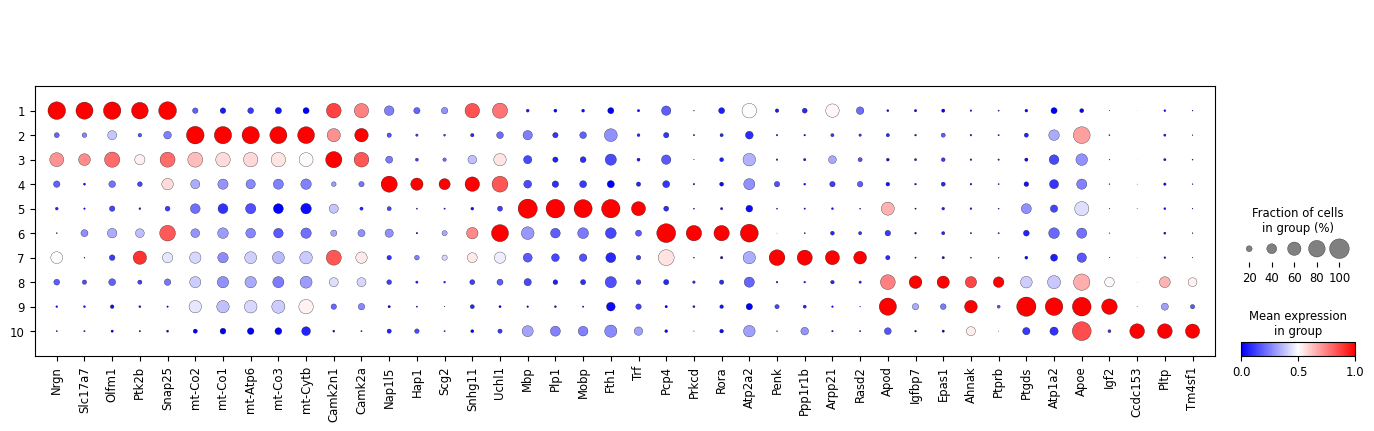

In [ ]:
# --- 点图 (Dot Plot) 可视化 ---

# sc.pl.dotplot：绘制点图，用于可视化多个基因（标记基因）在不同聚类（细胞群）中的表达模式。
sc.pl.dotplot(
    adata, 
    var_names=ordered_genes,  # [必选] 要可视化的基因列表，这里使用前面计算的 Top N 标记基因。
    groupby="clusters",       # [必选] 用于分组的离散变量，即 'adata.obs' 中的聚类标签。
    
    # standard_scale="var"：对基因（var）的表达值进行标准化。
    # 作用：将每个基因的表达值（跨所有聚类）缩放到 0 到 1 之间。这确保了高表达和低表达的基因可以在同一个颜色尺度上进行比较。
    standard_scale="var", 
    
    dendrogram=False,         # 是否计算和绘制聚类（clusters）或基因（var_names）的层次聚类树（树状图）。
    cmap="bwr"                # 用于连续表达值（点颜色）的颜色映射方案。'bwr' (蓝-白-红) 常见于差异表达可视化。
)

### 8.3 使用字典定义细胞类型

In [ ]:
# --- 定义聚类 ID 到细胞类型名称的映射字典 ---

# cluster2annotation：这是一个 Python 字典，用于将数值型（或字符串型）的聚类 ID 映射到其对应的生物学细胞类型名称。
# 这些对应关系通常是基于前一步骤中（如点图）对标记基因的分析结果确定的
cluster2annotation = {
    "1": "Exc",     # Exc: 兴奋性神经元 (Excitatory Neuron)
    "2": "Exc-mt",  # Exc-mt: 高线粒体百分比的兴奋性神经元（可能代表应激状态的细胞亚群）
    "3": "Exc",     # Exc: 兴奋性神经元
    "4": "Inh",     # Inh: 抑制性神经元 (Inhibitory Neuron)
    "5": "Olig",    # Olig: 少突胶质细胞 (Oligodendrocyte)
    "6": "Inh",     # Inh: 抑制性神经元
    "7": "Inh",     # Inh: 抑制性神经元
    "8": "Vas",     # Vas: 血管内皮细胞
    "9": "Ast",     # Ast: 星形胶质细胞 (Astrocyte)
    "10": "Ast"     # Ast: 星形胶质细胞
}

# --- 应用映射关系并创建新的 'celltype' 列 ---

# adata.obs["clusters"].map(cluster2annotation)：
# 使用 map() 方法，根据上方定义的字典，将 'adata.obs["clusters"]' 列中的聚类 ID 替换为对应的细胞类型名称
# adata.obs["celltype"] = ...：将映射后的结果存储到 'adata.obs' 的新列 'celltype' 中
adata.obs["celltype"] = adata.obs["clusters"].map(cluster2annotation)

# --- 强制转换数据类型 ---

# .astype(str)：将新创建的 'celltype' 列强制转换为字符串类型
# 目的：确保细胞类型标签被视为离散的、名义上的分类变量，便于后续的可视化和统计分析
adata.obs['celltype'] = adata.obs['celltype'].astype(str)

### 8.4 差异基因热图

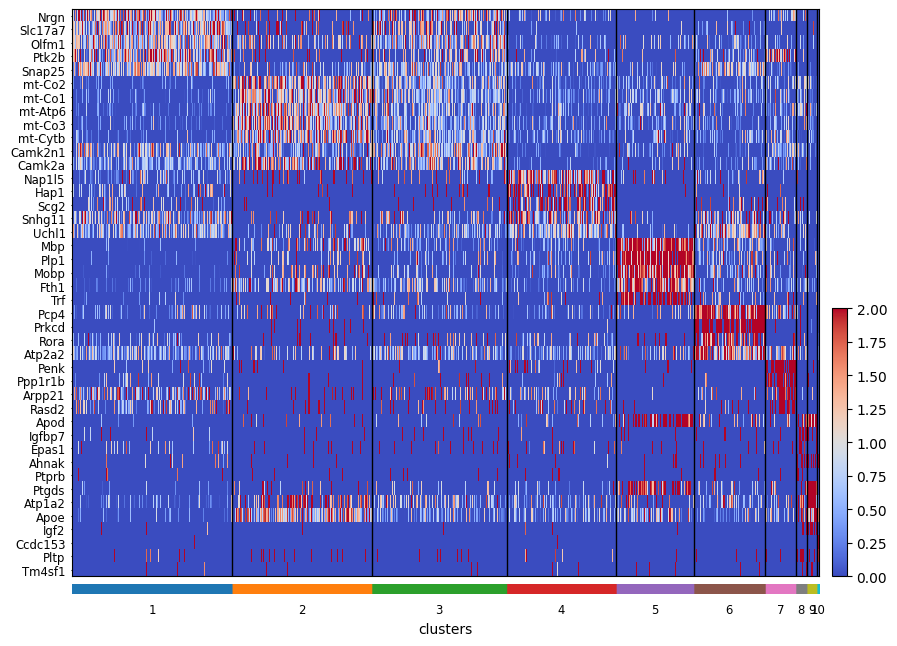

In [ ]:
# --- 热图 (Heatmap) 可视化 ---

# sc.pl.heatmap：绘制热图，用于可视化多个基因（标记基因）在不同聚类（细胞群）中的表达水平。
sc.pl.heatmap(
    adata, 
    var_names=ordered_genes,  # [必选] 要可视化的基因列表，即前面计算出的 Top N 标记基因。
    groupby="clusters",       # [必选] 用于分组的离散变量，即 'adata.obs' 中的聚类标签。
    cmap="coolwarm",          # 连续表达值使用的颜色映射方案。'coolwarm' 常见于显示差异和对比。
    swap_axes=True,           # 交换轴：将聚类（clusters）放在 Y 轴，基因（var_names）放在 X 轴。
                              # 目的：这通常使得热图更易于阅读，每个聚类对应一行。
    vmin=0,                   # 颜色映射的最小值（钳制/下界）。低于此值的表达值将显示为最低颜色。
    vmax=2,                   # 颜色映射的最大值（钳制/上界）。高于此值的表达值将显示为最高颜色。
                              # 目的：限制极端值对颜色尺度的影响，使颜色对比更集中于重要的差异区域。
    show_gene_labels=True     # 是否在 X 轴上显示完整的基因名称。
)

当然，也可以利用已有的marker给这些 spot 做基本细胞类型注释

In [6]:
markers_dict = {
    "Astrocytes": [
        "Sparc","Ttr","Clu","Gfap"
    ],
    "Excitatory_neurons": [
        "Camk2n1", "Ptk2b","Nrgn"
    ],
    "Inhibitory_neurons": [
        "Gad1", "Gad2"
    ],
    "Oligodendrocytes": [
        "Plp1", "Mbp", "Mobp", "Mal", "Trf"
    ],
    "Vasular_endothelial": [
        "Cldn5", "Flt1", "Pecam1"
    ]
}

In [ ]:
# 保存最终带有细胞类型注释的 AnnData 对象
adata.write('./downstream/process/basic_analysis/adata_labeled.h5ad')  

In [ ]:
adata = sc.read_h5ad('./downstream/process/basic_analysis/adata_labeled.h5ad')

### 8.5 使用字典绘制marker表达气泡图

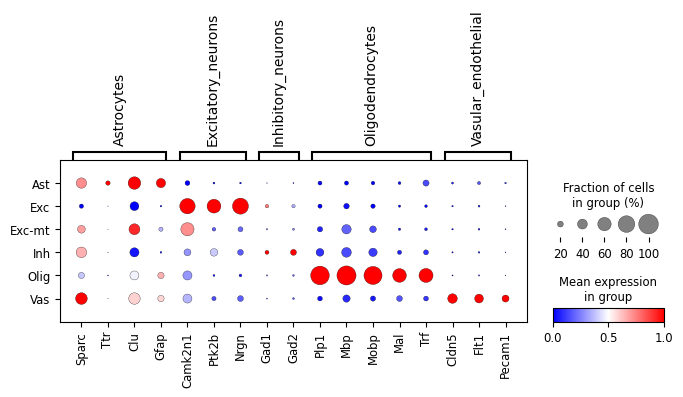

In [8]:
sc.pl.dotplot(adata,
              var_names=markers_dict,
              groupby='celltype',
              standard_scale="var",
              #dot_max=0.5, dot_min=0.3,
              cmap="bwr")

In [9]:
sc.tl.rank_genes_groups(adata, groupby="celltype", method="wilcoxon")

/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/chenao/.local/share/mamba/envs/st_env/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: inv

In [10]:
# 按差异基因进行排序
rg_df = sc.get.rank_genes_groups_df(adata, group=None) \
          .sort_values(["group","pvals_adj","scores"], ascending=[True, True, False])
rg_df

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,Ast,Ptgds,53.859955,NaN,0.000000,0.000000
1,Ast,Apoe,48.356934,NaN,0.000000,0.000000
2,Ast,Apod,42.039032,NaN,0.000000,0.000000
3,Ast,Atp1a2,40.390297,NaN,0.000000,0.000000
4,Ast,Igf2,40.078381,NaN,0.000000,0.000000
...,...,...,...,...,...,...
11854,Vas,Aspa,-0.827529,0.569918,0.407937,0.999200
11855,Vas,Olig2,-0.835469,0.630977,0.403454,0.999200
11365,Vas,Cideb,-0.001719,0.001441,0.998628,0.999628
11363,Vas,Arhgef10,0.000864,-0.033885,0.999311,0.999682


In [11]:
topN = 5
top_df = rg_df.groupby("group", as_index=False, sort=False).head(topN)
ordered_genes = top_df.groupby("group")["names"].apply(list).explode().drop_duplicates().tolist()

print(ordered_genes)

['Ptgds', 'Apoe', 'Apod', 'Atp1a2', 'Igf2', 'Nrgn', 'Olfm1', 'Snap25', 'Camk2n1', 'Ptk2b', 'mt-Co2', 'mt-Co1', 'mt-Atp6', 'mt-Co3', 'mt-Cytb', 'Uchl1', 'Pcp4', 'Nap1l5', 'Snhg11', 'Prkcd', 'Mbp', 'Plp1', 'Mobp', 'Fth1', 'Trf', 'Igfbp7', 'Epas1', 'Ahnak', 'Ptprb']


/tmp/ipykernel_246840/1682322783.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_df = rg_df.groupby("group", as_index=False, sort=False).head(topN)
/tmp/ipykernel_246840/1682322783.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ordered_genes = top_df.groupby("group")["names"].apply(list).explode().drop_duplicates().tolist()


### 8.6 差异基因平均表达热图

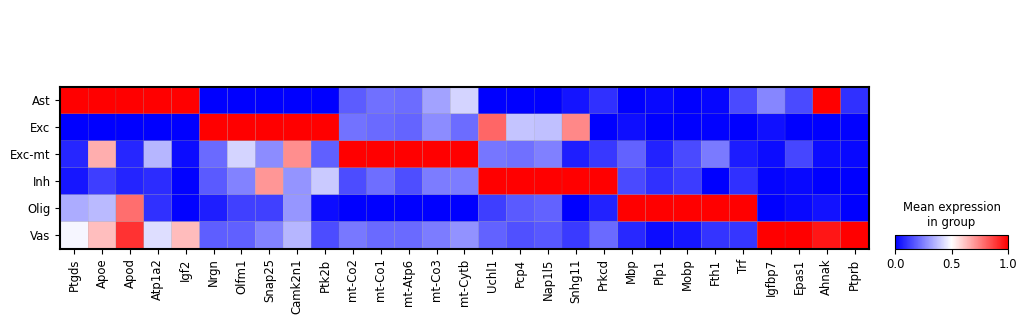

In [ ]:
# --- 矩阵图 (Matrix Plot) 可视化 ---

# sc.pl.matrixplot：绘制矩阵图，类似于点图和热图的结合体，用于可视化多个基因在不同细胞类型中的表达模式。
sc.pl.matrixplot(
    adata, 
    var_names=ordered_genes,  # [必选] 要可视化的基因列表，即前面计算出的 Top N 标记基因。
    groupby='celltype',       # [必选] 用于分组的离散变量，这里使用重新分配的 'celltype'（细胞类型名称）。
                              # 目的：用生物学名称代替数字聚类 ID 来展示标记基因的特异性。
    # standard_scale="var"：对基因（var）的表达值进行标准化。
    # 作用：将每个基因的表达值（跨所有细胞类型）缩放到 0 到 1 之间，确保高低表达基因可比较。
    standard_scale="var", 
    cmap="bwr"                # 用于连续表达值（矩阵颜色强度）的颜色映射方案。'bwr' (蓝-白-红) 常见于差异表达可视化。
)

### 8.7 差异基因表达小提琴图

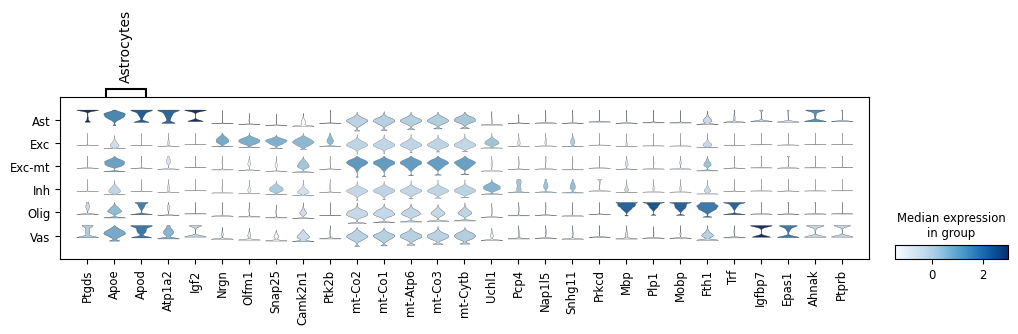

In [ ]:
# --- 堆叠小提琴图 (Stacked Violin Plot) 可视化 ---

# sc.pl.stacked_violin：绘制堆叠小提琴图，用于可视化多个基因在不同细胞类型中的表达分布。
# 相比点图和热图，小提琴图能展示更详细的表达分布形状（如双峰、偏态等）。
sc.pl.stacked_violin(
    adata,
    var_names=ordered_genes,      # [必选] 要可视化的基因列表，即前面计算出的 Top N 标记基因。
    groupby='celltype',           # [必选] 用于分组的离散变量，这里使用已注释的 'celltype' 名称。

    # var_group_positions=[(1,2)]：定义基因分组的起始和结束索引。
    # 作用：将 'ordered_genes' 列表中索引 1 到 2 的基因（即第 2 个和第 3 个基因）视为一个组。
    # 目的：允许在图中对相关的基因进行视觉上的组合。
    var_group_positions=[(1,2)],

    # var_group_labels=['Astrocytes']：定义上方基因组的标签。
    # 作用：为索引 1 到 2 的基因组添加 'Astrocytes' 的标签，方便识别。
    var_group_labels=['Astrocytes'],

    stripplot=False               # 是否在小提琴图上叠加绘制散点图（stripplot）。
    # 作用：设置为 False 可以使图形更清晰，尤其是在 Spot 数量较多时。
)

### 8.8 组织映射细胞类型

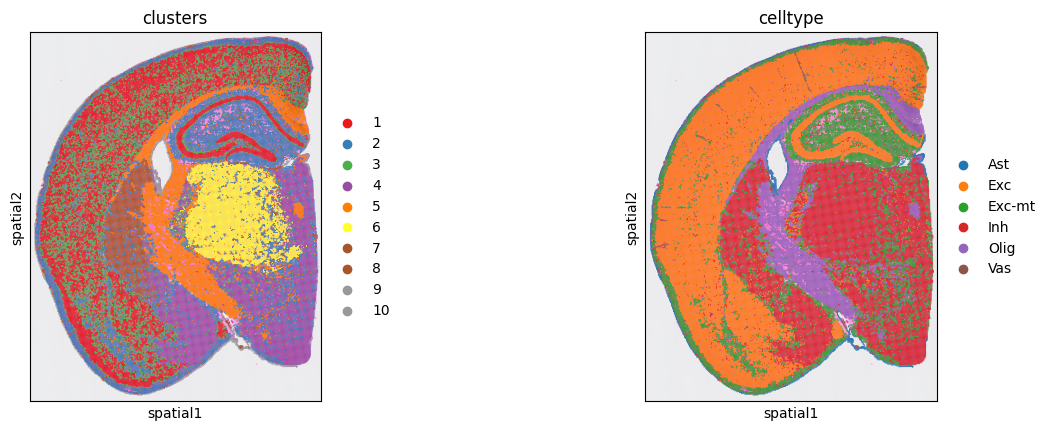

In [ ]:
# --- 空间散点图可视化 ---

# sq.pl.spatial_scatter：绘制 Spot 在组织切片物理空间中的位置图
sq.pl.spatial_scatter(
    adata,
    # color=["clusters","celltype"]：指定用于着色的变量
    # 目的：并排绘制两张图，一张按计算的聚类 ID 着色 ('clusters')，另一张按生物学注释 ('celltype') 着色
    # 这用于直接对比聚类结果和最终的细胞类型注释在组织中的空间分布
    color=["clusters","celltype"],
    library_id=lib_id, # [必选] 指定要绘制的组织切片的 ID
    size=1.2           # Spot 的大小，控制散点图中圆圈的半径
    # 可选参数如 img_id='hires' 可用于叠加组织图像背景
)

它将计算出的细胞类型 (celltype) 和原始聚类 (clusters) 映射回它们的物理位置，让分析者可以直观地观察到不同细胞类型在组织结构中的空间分布模式，例如神经元的皮层分层或胶质细胞的聚集区域

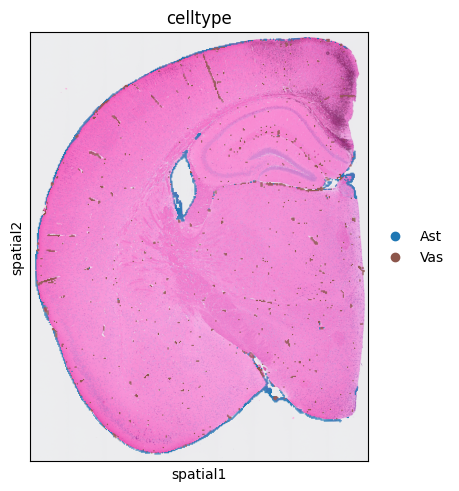

In [ ]:
# --- 空间散点图可视化（按特定组过滤）---

# sq.pl.spatial_scatter：绘制 Spot 在组织切片物理空间中的位置图。
sq.pl.spatial_scatter(
    adata,
    color=["celltype"],    # [必选] 用于着色的变量，即最终注释的细胞类型。
    
    # groups=["Vas","Ast"]：[关键参数] 指定只绘制 'celltype' 列中值为 "Vas" (血管细胞) 和 "Ast" (星形胶质细胞) 的 Spot。
    # 目的：过滤并高亮显示组织中特定细胞类型的空间分布，忽略其他所有细胞类型。
    groups=["Vas","Ast"],
    
    library_id=lib_id,     # [必选] 指定要绘制的组织切片的 ID。
    size=1.2               # Spot 的大小，控制散点图中圆圈的半径。
)

它在组织图像上隔离并突出显示特定的一组细胞类型（如血管细胞和星形胶质细胞），以便详细观察它们的空间分布模式、彼此间的邻近关系以及与组织结构的关系

### 8.9 绘制细胞类型UMAP图（美化）

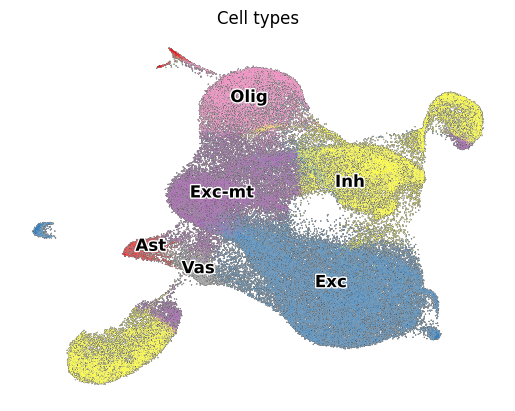

In [ ]:
# --- UMAP 细胞类型可视化 ---

# sc.pl.umap：绘制 UMAP 降维结果的二维散点图。
sc.pl.umap(
    adata, 
    color='celltype',          # [必选] 用于着色的离散变量，这里使用已注释的生物学细胞类型名称。
    add_outline=True,          # 为每个细胞类型簇群添加轮廓描边，使边界更清晰。
    
    # legend_loc='on data'：图例位置。
    # 作用：将图例（细胞类型名称）直接放置在对应的簇群中心，而非图表边缘。
    legend_loc='on data',
    
    legend_fontsize=12,        # 图例标签的字体大小设置为 12。
    legend_fontoutline=2,      # 图例标签字体周围添加描边（粗细为 2），提高在复杂背景上的可读性。
    frameon=False,             # 移除图表周围的边框和轴线，使图形更简洁。
    title='Cell types',        # 设置图表的标题。
    palette='Set1'             # 为离散变量（'celltype'）指定颜色调色板，'Set1' 是常用的鲜明配色方案。
)

In [67]:
from sklearn.neighbors import KernelDensity
def enhance_umap(adata, color='celltype', figsize=(6,6)):
    fig, ax = plt.subplots(figsize=figsize)

    # 绘制基础 UMAP 点图，不显示 legend、坐标轴框
    sc.pl.umap(
        adata,
        color=color,
        legend_loc=None,
        frameon=False,
        size=15,
        ax=ax,
        add_outline=True,
        show=False
    )
    for cell_type in adata.obs[color].unique():
        # 取出该细胞类型的 UMAP 坐标
        mask = adata.obs[color] == cell_type
        x = adata.obsm["X_umap"][mask, 0]
        y = adata.obsm["X_umap"][mask, 1]

        # 创建网格，用于 KDE
        x_min, x_max = x.min() - 0.5, x.max() + 0.5
        y_min, y_max = y.min() - 0.5, y.max() + 0.5
        xx, yy = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
        xy_train = np.vstack([x, y]).T
        xy_test = np.vstack([xx.ravel(), yy.ravel()]).T

        # 核密度估计 (Kernel Density Estimation)
        kde = KernelDensity(bandwidth=0.5, metric='euclidean')
        kde.fit(xy_train)

        Z = np.exp(kde.score_samples(xy_test))
        Z = Z.reshape(xx.shape)

        # 绘制轮廓线（只绘制密度最高 10% 的边界）
        plt.contour(
            xx, yy, Z,
            levels=[Z.max() * 0.1],
            colors='gray',
            linestyles='--',
            linewidths=1.2,
            alpha=0.75
        )
    cell_type_counts = adata.obs[color].value_counts(normalize=True) * 100
    for cell_type, percentage in cell_type_counts.items():
        mask = adata.obs[color] == cell_type
        x = np.median(adata.obsm["X_umap"][mask, 0])
        y = np.median(adata.obsm["X_umap"][mask, 1])

        ax.text(
            x, y, f"{cell_type}",  # 也可以加百分比 f"{cell_type} ({percentage:.1f}%)"
            fontsize=10,
            ha="center",
            color="black",
            bbox=dict(
                facecolor='white',  # 白色背景
                edgecolor='none',
                alpha=0.65,
                boxstyle="round,pad=0.4"  # 圆角
            )
        )
    ax = plt.gca()
    ax.set_xlabel('UMAP1', fontsize=10)
    ax.set_ylabel('UMAP2', fontsize=10)

    # 获取坐标轴范围
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    x_range = x_max - x_min
    y_range = y_max - y_min
    aspect_ratio = (fig.get_size_inches()[0] / fig.get_size_inches()[1]) * (y_range / x_range)

    # 箭头长度
    dx = x_range * 0.1 * aspect_ratio
    dy = y_range * 0.1 * aspect_ratio
    head_width = dy * 0.1
    head_length = dx * 0.1

    # X轴箭头
    ax.arrow(x_min, y_min, dx, 0, head_width=head_width, head_length=head_length, fc='black', ec='black')
    # Y轴箭头
    ax.arrow(x_min, y_min, 0, dy, head_width=head_width, head_length=head_length, fc='black', ec='black')

    # 箭头标签
    label_offset = dx * 0.15
    ax.text(x_min + dx/2, y_min - label_offset, 'UMAP1', ha='center', va='top', fontsize=10)
    ax.text(x_min - label_offset, y_min + dy/2, 'UMAP2', rotation=90, ha='right', va='center', fontsize=10)

代码参考来源**生信大杂烩**[Scanpy可视化技巧--UMAP图优化](https://mp.weixin.qq.com/s/mQfv__BXVp_xWBMQofaAkQ)

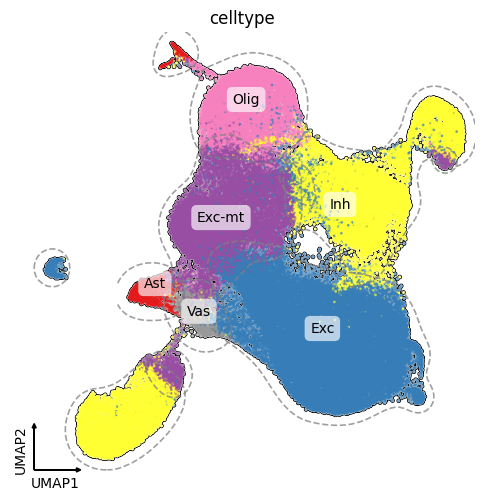

In [68]:
enhance_umap(adata, color='celltype', figsize=(6,6))

### 8.10 绘制细胞类型marker基因组织切片表达

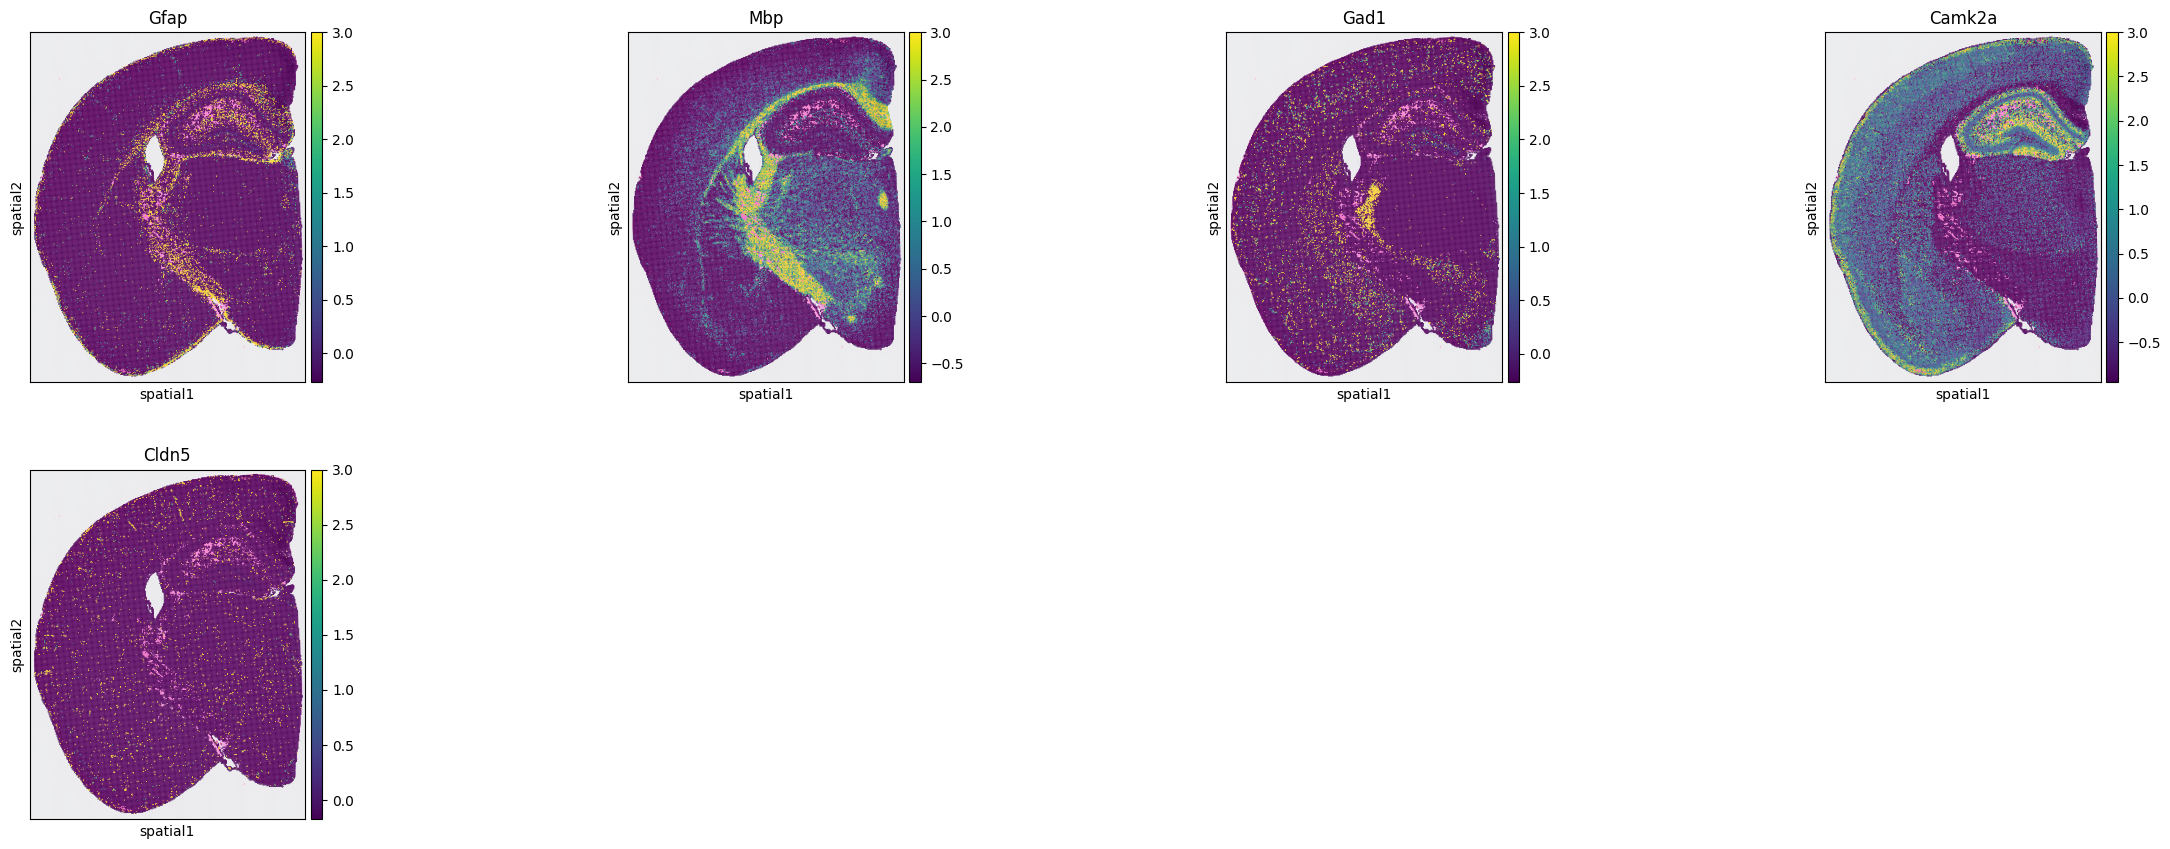

In [ ]:
# --- 空间散点图可视化：多种标记基因对比 ---

# sq.pl.spatial_scatter：绘制 Spot 在组织切片物理空间中的位置图。
sq.pl.spatial_scatter(
    adata,
    # color：指定要可视化的基因列表，将为列表中的每个基因生成一个子图。
    color=[
        "Gfap",   # 星形胶质细胞 (Astrocyte) 标记基因
        "Mbp",    # 少突胶质细胞 (Oligodendrocyte) 标记基因
        "Gad1",   # 抑制性神经元 (Inhibitory Neuron) 标记基因
        "Camk2a", # 兴奋性神经元 (Excitatory Neuron) 标记基因
        "Cldn5"   # 内皮细胞 (Endothelial/Vascular) 标记基因
    ],
    library_id=lib_id, # [必选] 指定要绘制的组织切片的 ID。
    size=1.2           # Spot 的大小，控制散点图中圆圈的半径。
    # 目的：通过并排对比这些关键标记基因的表达热点区域，直观地确认不同细胞类型在组织中的空间分布和组织结构。
)

本基础分析流程涵盖了空间转录组数据的预处理、降维、聚类与生物学注释。首先，数据通过 Pearson 残差标准化进行方差稳定和噪声移除，随后通过 PCA 进行线性降维，并执行了缩放与极值钳制以保障数据质量。在 UMAP 降维之前，使用 sc.pp.neighbors 构建了邻域拓扑图。在特征选择阶段，通过莫兰系数识别的 SVGs 证实为 HVGs 的子集。聚类完成后，使用 Wilcoxon 检验确定了各簇的标记基因，并通过点图、热图等多种可视化方式进行了验证，从而完成了细胞类型（celltype）注释。最终，通过 sq.pl.spatial_scatter 将细胞类型和标记基因的表达模式精确地映射回组织物理空间，确认了细胞群体的空间分布与组织结构的一致性，完成了从计数矩阵到空间生物学洞察的整个流程

# 环境信息

In [ ]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/.local/share/mamba/envs/st_env:
#
# Name                               Version          Build                 Channel
_libgcc_mutex                        0.1              conda_forge           conda-forge
_openmp_mutex                        4.5              2_gnu                 conda-forge
_r-mutex                             1.0.1            anacondar_1           conda-forge
absl-py                              2.3.1            pypi_0                pypi
access                               1.1.9            pypi_0                pypi
adwaita-icon-theme                   48.1             unix_1                conda-forge
affine                               2.4.0            pypi_0                pypi
aiobotocore                          2.24.1           pypi_0                pypi
aiofiles                             24.1.0           pypi_0                pypi
aiohappyeyeballs                     2.6.1            pypi_0                pypi
ai

CompletedProcess(args=['conda', 'list'], returncode=0)

In [2]:
subprocess.run(['pip', 'list'])

Package                   Version        Build Editable project location
------------------------- -------------- ----- ---------------------------------------------------------------
absl-py                   2.3.1
access                    1.1.9
affine                    2.4.0
aiobotocore               2.24.1
aiofiles                  24.1.0
aiohappyeyeballs          2.6.1
aiohttp                   3.12.15
aioitertools              0.12.0
aiosignal                 1.4.0
anndata                   0.11.4
anndata2ri                1.3.2
annoy                     1.17.3
anyio                     4.10.0
argcomplete               3.6.2
argon2-cffi               25.1.0
argon2-cffi-bindings      25.1.0
array-api-compat          1.12.0
arrow                     1.3.0
asciitree                 0.3.3
asttokens                 3.0.0
async-lru                 2.0.5
async-timeout             5.0.1
attrs                     25.3.0
babel                     2.17.0
bbknn                     1.6.0
bea

CompletedProcess(args=['pip', 'list'], returncode=0)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 